# Olist E-Commerce — Exploratory Data Analysis & Visualization
### A read-only exploration of nine related CSV files

**Scope:** understand the data, investigate business patterns, and visualize findings. Only analysis-specific handling is used: date parsing, cardinality-safe joins, aggregation, and explicitly reported eligibility masks.

**Not included:** a general cleaning pipeline, missing-value imputation, global outlier removal, encoding, scaling, model features, train/test splitting, model training, or deployment. No cleaned dataset is exported. Source CSVs remain unchanged.

This is a **retrospective historical snapshot**, not a live operational dashboard. Statuses are final snapshot statuses; payments have no transaction timestamps. Item value is not profit or recognized revenue. Prices are displayed as BRL under the dataset's Brazilian-commerce context; there is no currency column.

**How to read:** each section states its question, shows reproducible code and charts, then explains the result and limitations. All nine files are covered, including geolocation and category translation. Calculations and conclusions are recomputed from the files when you run all cells.

## Contents
1. Setup and source manifest
2. Structure, missingness, duplicates and relationships
3. Analysis-specific eligibility and data issues
4. Order-level view and headline metrics
5. Time patterns and order statuses
6. Basket value and freight
7. Delivery experience
8. Reviews and their relationship to delivery
9. Payments and reconciliation
10. Products and categories
11. Sellers
12. Customers and observed repeat behavior
13. Geography
14. Exploratory associations
15. Findings, limitations and integrity checks


## 1. Setup and source manifest

### Local Jupyter / VS Code
Open this notebook and run all cells from top to bottom. The loader searches `data/raw/` relative to the working directory or its parent, then the supplied local `Downloads/archive-3/` folder. To use another directory, set `DATA_DIR_OVERRIDE` in the next cell.

### Google Colab
Upload the notebook. Put the nine CSV files together in a folder accessible to Colab, such as `/content/data/raw`, and set `DATA_DIR_OVERRIDE` accordingly. Alternatively, mount your own Google Drive using Colab's Files panel and point to its dataset folder. There is **no automatic Drive mount, download, package installation, or upload** in this notebook. Common Colab runtimes include pandas, NumPy, matplotlib and seaborn; a local environment needs those packages plus IPython.

The executed outputs below come from the original attached local archive. Opening them does not require the CSVs; rerunning does. The notebook does not download or redistribute the raw files. Exact source version and license attachment remain unverified; the project brief identifies the [Olist Kaggle dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). Follow the original dataset's terms before redistributing source data.


In [1]:
from pathlib import Path
import hashlib
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display, Markdown

DATA_DIR_OVERRIDE = None  # Example: Path('/content/data/raw')
FILES = {
    'orders': 'olist_orders_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'translation': 'product_category_name_translation.csv',
}
candidates = ([Path(DATA_DIR_OVERRIDE).expanduser()] if DATA_DIR_OVERRIDE is not None else [
    Path.cwd() / 'data/raw', Path.cwd().parent / 'data/raw',
    Path('/content/data/raw'), Path.home() / 'Downloads/archive-3',
])
DATA_DIR = next((p for p in candidates if all((p / f).is_file() for f in FILES.values())), None)
if DATA_DIR is None:
    raise FileNotFoundError('Set DATA_DIR_OVERRIDE to the folder containing all nine CSVs: ' + ', '.join(FILES.values()))

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0)
COLORS = {'teal': '#087F8C', 'navy': '#243B53', 'orange': '#D97732', 'red': '#BC4749', 'gray': '#7B8794'}
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlepad': 14, 'figure.facecolor': 'white'})
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

def note(text):
    display(Markdown(text))

def table(frame, max_rows=30):
    display(frame.style.format(precision=2, thousands=',').hide(axis='index') if len(frame) <= max_rows else frame)

def horizontal_bars(series, title, xlabel, color=None, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, max(4, len(series) * 0.35)))
    series.sort_values().plot.barh(ax=ax, color=color or COLORS['teal'])
    ax.set(title=title, xlabel=xlabel, ylabel='')
    ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=5))
    if xlabel == 'BRL' and series.max() >= 1_000_000:
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, pos: f'{value / 1_000_000:.1f}'))
        ax.set_xlabel('Item/payment value (million BRL)')
    else:
        ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
    return ax

runtime = pd.DataFrame({'Component': ['Python', 'pandas', 'NumPy', 'matplotlib', 'seaborn'],
                       'Version': [platform.python_version(), pd.__version__, np.__version__, matplotlib.__version__, sns.__version__]})
table(runtime)
print('Resolved dataset directory:', DATA_DIR)


Resolved dataset directory: /Users/hadyahmed/Downloads/archive-3


Component,Version
Python,3.14.3
pandas,3.0.3
NumPy,2.5.0
matplotlib,3.11.0
seaborn,0.13.2


In [2]:
# Raw frames remain untouched. All analysis views are separate objects.
raw = {}
manifest_rows = []
for name, filename in FILES.items():
    path = DATA_DIR / filename
    headers = pd.read_csv(path, nrows=0).columns
    string_columns = [c for c in headers if c.endswith('_id') or 'zip_code_prefix' in c]
    raw[name] = pd.read_csv(path, dtype={c: 'string' for c in string_columns})
    manifest_rows.append({'Table': name, 'File': filename, 'Rows': len(raw[name]),
                          'Columns': raw[name].shape[1], 'Size MiB': path.stat().st_size / 1024**2,
                          'SHA256': hashlib.sha256(path.read_bytes()).hexdigest()})
manifest = pd.DataFrame(manifest_rows)
initial_hashes = dict(zip(manifest['File'], manifest['SHA256']))
table(manifest.drop(columns='SHA256'))
note(f"**Source coverage:** {len(raw)} complete CSV files loaded; {len(raw['orders']):,} order records. IDs and ZIP prefixes are text. Blank fields are recognized using pandas' default CSV null conventions.")


Table,File,Rows,Columns,Size MiB
orders,olist_orders_dataset.csv,"99,441",8,16.84
items,olist_order_items_dataset.csv,"112,650",7,14.72
payments,olist_order_payments_dataset.csv,"103,886",5,5.51
reviews,olist_order_reviews_dataset.csv,"99,224",7,13.78
customers,olist_customers_dataset.csv,"99,441",5,8.62
products,olist_products_dataset.csv,"32,951",9,2.27
sellers,olist_sellers_dataset.csv,"3,095",4,0.17
geolocation,olist_geolocation_dataset.csv,"1,000,163",5,58.44
translation,product_category_name_translation.csv,71,2,0.00


**Source coverage:** 9 complete CSV files loaded; 99,441 order records. IDs and ZIP prefixes are text. Blank fields are recognized using pandas' default CSV null conventions.

## 2. Structure, missingness, duplicates and relationships

**Questions:** What does one row mean? Which columns are missing? Which apparent duplicates are legitimate repeated relationships?

| Table | Row grain | Candidate key |
|---|---|---|
| orders | One order | order_id |
| items | One numbered order line | order_id + order_item_id |
| payments | One payment sequence for an order | order_id + payment_sequential |
| reviews | One review/order association | review_id + order_id |
| customers | One order-specific customer record | customer_id |
| products | One product snapshot | product_id |
| sellers | One seller snapshot | seller_id |
| geolocation | One location observation; ZIPs repeat | No unique ZIP key |
| translation | One Portuguese category translation | product_category_name |

`customer_unique_id` links observed purchases from the same buyer. It is not the customer-to-order join key. A repeated order ID in items or payments is expected, not a row to delete.


In [3]:
schema_rows = []
for name, frame in raw.items():
    for column in frame:
        schema_rows.append({'Table': name, 'Column': column, 'Parsed dtype': str(frame[column].dtype),
                            'Missing': int(frame[column].isna().sum()),
                            'Missing %': 100 * frame[column].isna().mean(),
                            'Distinct non-null': frame[column].nunique()})
schema = pd.DataFrame(schema_rows)
# One displayed schema per table keeps all exact column names visible.
for name in FILES:
    note(f'### {name.title()} — exact source columns')
    table(schema.loc[schema['Table'].eq(name)].drop(columns='Table'))


### Orders — exact source columns

Column,Parsed dtype,Missing,Missing %,Distinct non-null
order_id,string,0,0.00,"99,441"
customer_id,string,0,0.00,"99,441"
order_status,str,0,0.00,8
order_purchase_timestamp,str,0,0.00,"98,875"
order_approved_at,str,160,0.16,"90,733"
order_delivered_carrier_date,str,"1,783",1.79,"81,018"
order_delivered_customer_date,str,"2,965",2.98,"95,664"
order_estimated_delivery_date,str,0,0.00,459


### Items — exact source columns

Column,Parsed dtype,Missing,Missing %,Distinct non-null
order_id,string,0,0.00,"98,666"
order_item_id,string,0,0.00,21
product_id,string,0,0.00,"32,951"
seller_id,string,0,0.00,"3,095"
shipping_limit_date,str,0,0.00,"93,318"
price,float64,0,0.00,"5,968"
freight_value,float64,0,0.00,"6,999"


### Payments — exact source columns

Column,Parsed dtype,Missing,Missing %,Distinct non-null
order_id,string,0,0.00,"99,440"
payment_sequential,int64,0,0.00,29
payment_type,str,0,0.00,5
payment_installments,int64,0,0.00,24
payment_value,float64,0,0.00,"29,077"


... (8 outputs left out)

### Geolocation — exact source columns

Column,Parsed dtype,Missing,Missing %,Distinct non-null
geolocation_zip_code_prefix,string,0,0.00,"19,015"
geolocation_lat,float64,0,0.00,"717,363"
geolocation_lng,float64,0,0.00,"717,615"
geolocation_city,str,0,0.00,"8,011"
geolocation_state,str,0,0.00,27


### Translation — exact source columns

Column,Parsed dtype,Missing,Missing %,Distinct non-null
product_category_name,str,0,0.00,71
product_category_name_english,str,0,0.00,71


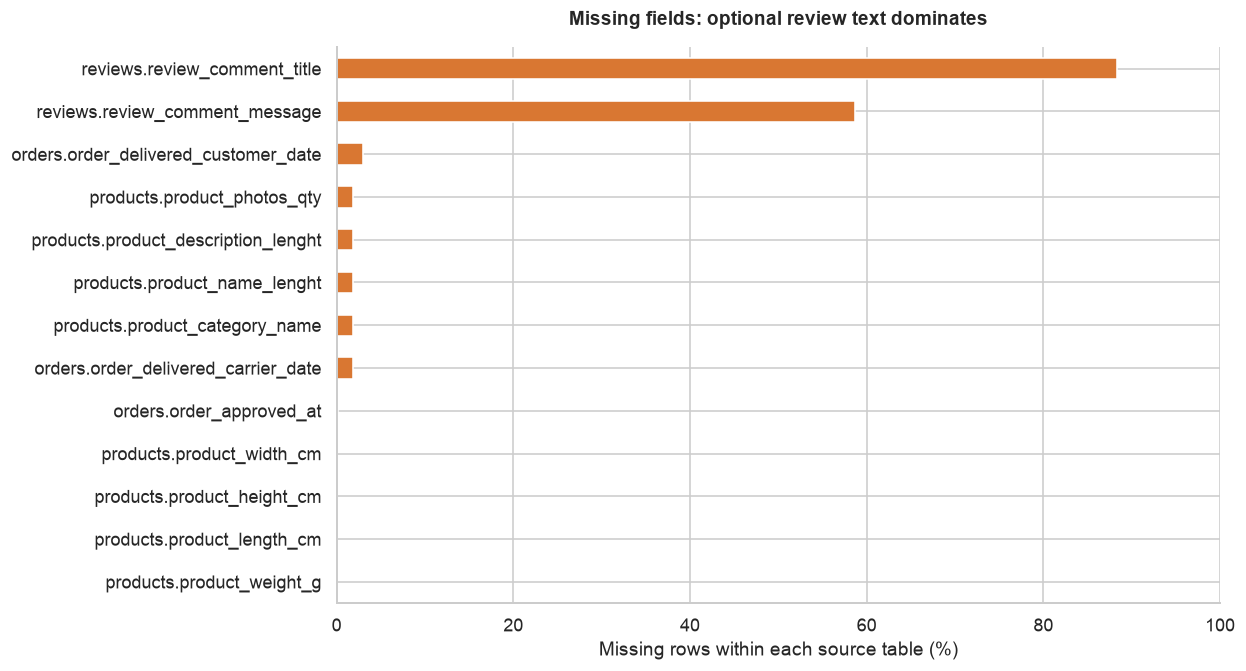

**Interpretation:** missing review text is not a missing review score. Missing delivery dates represent unknown observed delivery outcomes. No numeric or date values are imputed in this notebook.

In [4]:
missing = schema[schema['Missing'] > 0].copy()
missing['Field'] = missing['Table'] + '.' + missing['Column']
fig, ax = plt.subplots(figsize=(11, 6))
if len(missing):
    missing.set_index('Field')['Missing %'].sort_values().plot.barh(ax=ax, color=COLORS['orange'])
ax.set(title='Missing fields: optional review text dominates', xlabel='Missing rows within each source table (%)', ylabel='')
ax.set_xlim(0, 100)
plt.tight_layout(); plt.show()
note('**Interpretation:** missing review text is not a missing review score. Missing delivery dates represent unknown observed delivery outcomes. No numeric or date values are imputed in this notebook.')


In [5]:
KEYS = {'orders': ['order_id'], 'items': ['order_id', 'order_item_id'],
        'payments': ['order_id', 'payment_sequential'], 'reviews': ['review_id', 'order_id'],
        'customers': ['customer_id'], 'products': ['product_id'], 'sellers': ['seller_id'],
        'translation': ['product_category_name']}
duplicate_summary = pd.DataFrame([
    {'Table': name, 'Exact duplicate rows': int(frame.duplicated().sum()),
     'Key': ' + '.join(KEYS[name]) if name in KEYS else 'No unique ZIP key',
     'Excess key duplicates': int(frame.duplicated(KEYS[name]).sum()) if name in KEYS else pd.NA}
    for name, frame in raw.items()
])
table(duplicate_summary)
print('Repeated review_id values beyond first:', raw['reviews']['review_id'].duplicated().sum())
note('**Decision:** do not remove source rows. Exact repeated geography observations are counted here; geographic plots later use an explicitly aggregated, plot-only view. Review IDs alone are not unique, while their review/order pairs are.')


Repeated review_id values beyond first: 814


Table,Exact duplicate rows,Key,Excess key duplicates
orders,0,order_id,0
items,0,order_id + order_item_id,0
payments,0,order_id + payment_sequential,0
reviews,0,review_id + order_id,0
customers,0,customer_id,0
products,0,product_id,0
sellers,0,seller_id,0
geolocation,"261,831",No unique ZIP key,
translation,0,product_category_name,0


**Decision:** do not remove source rows. Exact repeated geography observations are counted here; geographic plots later use an explicitly aggregated, plot-only view. Review IDs alone are not unique, while their review/order pairs are.

Relationship,Non-null source rows,Null source rows,Unmatched non-null rows
orders.customer_id → customers.customer_id,"99,441",0,0
items.order_id → orders.order_id,"112,650",0,0
payments.order_id → orders.order_id,"103,886",0,0
reviews.order_id → orders.order_id,"99,224",0,0
items.product_id → products.product_id,"112,650",0,0
items.seller_id → sellers.seller_id,"112,650",0,0
products.product_category_name → translation.product_category_name,"32,341",610,13
customers.customer_zip_code_prefix → geolocation.geolocation_zip_code_prefix,"99,441",0,278
sellers.seller_zip_code_prefix → geolocation.geolocation_zip_code_prefix,"3,095",0,7


Child table,Orders with rows,Orders without rows,Orders with multiple rows,Maximum rows per order
items,"98,666",775,"9,803",21
payments,"99,440",1,"2,961",29
reviews,"98,673",768,547,3


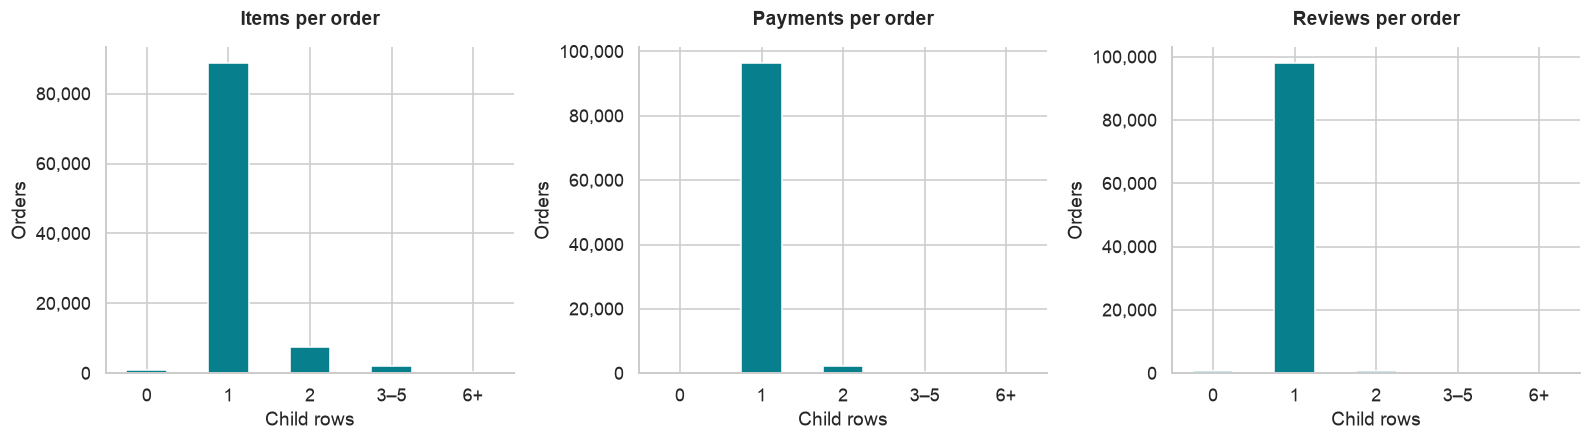

**Join rule:** aggregate items, payments and reviews independently before joining them to orders. Joining all raw child tables directly would multiply rows and inflate totals. Geography is also many-to-one only after an explicit plot-level aggregation.

In [6]:
relations = [
    ('orders','customer_id','customers','customer_id'),
    ('items','order_id','orders','order_id'), ('payments','order_id','orders','order_id'),
    ('reviews','order_id','orders','order_id'), ('items','product_id','products','product_id'),
    ('items','seller_id','sellers','seller_id'),
    ('products','product_category_name','translation','product_category_name'),
    ('customers','customer_zip_code_prefix','geolocation','geolocation_zip_code_prefix'),
    ('sellers','seller_zip_code_prefix','geolocation','geolocation_zip_code_prefix'),
]
fk_rows=[]
for child, col, parent, key in relations:
    source=raw[child][col]
    fk_rows.append({'Relationship': f'{child}.{col} → {parent}.{key}',
                    'Non-null source rows': int(source.notna().sum()), 'Null source rows': int(source.isna().sum()),
                    'Unmatched non-null rows': int((source.notna() & ~source.isin(raw[parent][key])).sum())})
fk_audit=pd.DataFrame(fk_rows)
table(fk_audit)

multiplicity=[]
for name in ['items','payments','reviews']:
    counts=raw[name].groupby('order_id').size()
    multiplicity.append({'Child table':name,'Orders with rows':len(counts),
                         'Orders without rows':len(raw['orders'])-len(counts),
                         'Orders with multiple rows':int(counts.gt(1).sum()),'Maximum rows per order':int(counts.max())})
table(pd.DataFrame(multiplicity))
fig, axes=plt.subplots(1,3,figsize=(14,4))
for name, ax in zip(['items','payments','reviews'],axes):
    counts=raw[name].groupby('order_id').size().reindex(raw['orders']['order_id'],fill_value=0)
    bins=pd.cut(counts,bins=[-1,0,1,2,5,np.inf],labels=['0','1','2','3–5','6+'])
    bins.value_counts(sort=False).plot.bar(ax=ax,color=COLORS['teal'],rot=0)
    ax.set(title=f'{name.title()} per order',xlabel='Child rows',ylabel='Orders')
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout();plt.show()
note('**Join rule:** aggregate items, payments and reviews independently before joining them to orders. Joining all raw child tables directly would multiply rows and inflate totals. Geography is also many-to-one only after an explicit plot-level aggregation.')


## 3. Analysis-specific handling and eligibility

This section **does not produce cleaned data**. It parses dates in working copies and records problems. Raw frames and files remain intact. A bad shipping timestamp does not cause the entire order to be deleted. Masks are applied only to the calculation that needs them.

- Preserve source wall-clock timestamps; the source timezone is undocumented.
- Treat calendar-day lateness as the main descriptive rule, and show the exact-timestamp alternative.
- For order-level review summaries, use the first answer on or after purchase, breaking ties by review ID. Retain all raw reviews for the raw score distribution.
- Use unknown categories only as display groups; never overwrite source categories.
- Keep large monetary values in all totals; logarithmic chart axes make long tails visible without trimming.


In [7]:
date_columns = {
    'orders': ['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date',
               'order_delivered_customer_date','order_estimated_delivery_date'],
    'items': ['shipping_limit_date'],
    'reviews': ['review_creation_date','review_answer_timestamp'],
}
data={name:frame.copy() for name,frame in raw.items()}
parse_rows=[]
for name, columns in date_columns.items():
    for column in columns:
        parsed=pd.to_datetime(raw[name][column],errors='coerce')
        parse_rows.append({'Table':name,'Field':column,'Nonblank parse failures':int((raw[name][column].notna() & parsed.isna()).sum()),
                           'First observed':parsed.min(),'Last observed':parsed.max()})
        data[name][column]=parsed
table(pd.DataFrame(parse_rows))
orders=data['orders'];items=data['items'];payments=data['payments'];reviews=data['reviews']
customers=data['customers'];products=data['products'];sellers=data['sellers'];geo=data['geolocation']

issues=[]
def issue(label,mask,unit,handling):
    issues.append({'Issue':label,'Affected':int(mask.sum()),'Unit':unit,'Analysis-specific handling':handling})
for left,right in [('order_approved_at','order_purchase_timestamp'),
                   ('order_delivered_carrier_date','order_purchase_timestamp'),
                   ('order_delivered_carrier_date','order_approved_at'),
                   ('order_delivered_customer_date','order_delivered_carrier_date')]:
    issue(f'{left} precedes {right}',orders[left]<orders[right],'orders','Exclude only from affected elapsed-time calculation')
issue('Delivered status without delivery timestamp',orders['order_status'].eq('delivered') & orders['order_delivered_customer_date'].isna(),'orders','No observed duration or delivery label')
issue('Other status with delivery timestamp',orders['order_status'].ne('delivered') & orders['order_delivered_customer_date'].notna(),'orders','Retain timestamp-based analysis and flag status discrepancy')
review_join=reviews.merge(orders[['order_id','order_purchase_timestamp','order_delivered_customer_date']],on='order_id',validate='many_to_one')
issue('Review answer before purchase',review_join['review_answer_timestamp']<review_join['order_purchase_timestamp'],'review rows','Exclude only from valid first-answer/time analyses')
issue('Zero product weight',products['product_weight_g'].eq(0),'products','Not a valid positive weight in weight relationship plot')
issue('Zero payment amount',payments['payment_value'].eq(0),'payment rows','Retain; show separately from positive log distribution')
issue('Zero installment count',payments['payment_installments'].eq(0),'payment rows','Retain and disclose')
issue('Shipping deadline after 2018',items['shipping_limit_date'].gt('2018-12-31'),'item rows','Retain; do not treat deadline as an observed event')
quality_issues=pd.DataFrame(issues)
table(quality_issues)
note('**Counts overlap.** Do not sum issue counts to estimate affected orders. None of these rules removes rows globally.')


Table,Field,Nonblank parse failures,First observed,Last observed
orders,order_purchase_timestamp,0,2016-09-04 21:15:19,2018-10-17 17:30:18
orders,order_approved_at,0,2016-09-15 12:16:38,2018-09-03 17:40:06
orders,order_delivered_carrier_date,0,2016-10-08 10:34:01,2018-09-11 19:48:28
orders,order_delivered_customer_date,0,2016-10-11 13:46:32,2018-10-17 13:22:46
orders,order_estimated_delivery_date,0,2016-09-30 00:00:00,2018-11-12 00:00:00
items,shipping_limit_date,0,2016-09-19 00:15:34,2020-04-09 22:35:08
reviews,review_creation_date,0,2016-10-02 00:00:00,2018-08-31 00:00:00
reviews,review_answer_timestamp,0,2016-10-07 18:32:28,2018-10-29 12:27:35


Issue,Affected,Unit,Analysis-specific handling
order_approved_at precedes order_purchase_timestamp,0,orders,Exclude only from affected elapsed-time calculation
order_delivered_carrier_date precedes order_purchase_timestamp,166,orders,Exclude only from affected elapsed-time calculation
order_delivered_carrier_date precedes order_approved_at,"1,359",orders,Exclude only from affected elapsed-time calculation
order_delivered_customer_date precedes order_delivered_carrier_date,23,orders,Exclude only from affected elapsed-time calculation
Delivered status without delivery timestamp,8,orders,No observed duration or delivery label
Other status with delivery timestamp,6,orders,Retain timestamp-based analysis and flag status discrepancy
Review answer before purchase,63,review rows,Exclude only from valid first-answer/time analyses
Zero product weight,4,products,Not a valid positive weight in weight relationship plot
Zero payment amount,9,payment rows,Retain; show separately from positive log distribution
Zero installment count,2,payment rows,Retain and disclose


**Counts overlap.** Do not sum issue counts to estimate affected orders. None of these rules removes rows globally.

## 4. Cardinality-safe order view and headline metrics

**Question:** What is the scale of recorded activity, without multiplying order rows?

All joins below validate cardinality. The order-level view retains every order. Missing child totals remain missing, not zero. Item count and duration columns exist for descriptive summaries and charts only; they are not a training feature pipeline.


In [8]:
item_by_order=items.groupby('order_id').agg(
    item_count=('order_item_id','size'), product_count=('product_id','nunique'),
    seller_count=('seller_id','nunique'), item_value=('price','sum'), freight_value=('freight_value','sum'))
payment_by_order=payments.groupby('order_id').agg(payment_value=('payment_value','sum'),payment_rows=('payment_sequential','size'))
review_counts=reviews.groupby('order_id').size().rename('review_rows')
valid_review_rows=review_join.loc[review_join['review_answer_timestamp'].ge(review_join['order_purchase_timestamp'])].copy()
first_review=valid_review_rows.sort_values(['review_answer_timestamp','review_id']).drop_duplicates('order_id',keep='first')
order_view=(orders.merge(customers,on='customer_id',how='left',validate='one_to_one')
            .merge(item_by_order,on='order_id',how='left',validate='one_to_one')
            .merge(payment_by_order,on='order_id',how='left',validate='one_to_one')
            .merge(review_counts,on='order_id',how='left',validate='one_to_one')
            .merge(first_review[['order_id','review_score','review_answer_timestamp']],on='order_id',how='left',validate='one_to_one'))
order_view['delivery_days']=(order_view['order_delivered_customer_date']-order_view['order_purchase_timestamp']).dt.total_seconds()/86400
order_view['promise_days']=(order_view['order_estimated_delivery_date']-order_view['order_purchase_timestamp']).dt.total_seconds()/86400
order_view['delay_calendar_days']=(order_view['order_delivered_customer_date'].dt.normalize()-order_view['order_estimated_delivery_date'].dt.normalize()).dt.days
valid_delivery=order_view['delivery_days'].ge(0) & order_view['order_estimated_delivery_date'].notna()
# Nullable flag: unknown delivery is never converted into an on-time order.
order_view['late_calendar']=pd.Series(pd.NA,index=order_view.index,dtype='boolean')
order_view.loc[valid_delivery,'late_calendar']=order_view.loc[valid_delivery,'delay_calendar_days'].gt(0)

assert len(order_view)==len(orders) and order_view['order_id'].is_unique
assert np.isclose(order_view['item_value'].sum(),items['price'].sum())
assert np.isclose(order_view['freight_value'].sum(),items['freight_value'].sum())
assert np.isclose(order_view['payment_value'].sum(),payments['payment_value'].sum())
metrics=pd.DataFrame([
    ('Placed orders',len(order_view),'All snapshot statuses'),
    ('Distinct observed buyers',customers['customer_unique_id'].nunique(),'Across the available snapshot'),
    ('Item sales value (BRL)',items['price'].sum(),'Recorded item lines; not profit'),
    ('Freight charges (BRL)',items['freight_value'].sum(),'Recorded item lines; not shipping cost'),
    ('Payment snapshot total (BRL)',payments['payment_value'].sum(),'Undated payment records'),
    ('Average item order value (BRL)',item_by_order['item_value'].mean(),'Orders with at least one item'),
    ('Observed delivery coverage (%)',100*valid_delivery.mean(),'Valid delivery + estimate / all orders'),
    ('Calendar-late among observed deliveries (%)',100*order_view.loc[valid_delivery,'late_calendar'].mean(),'Unknown deliveries excluded'),
],columns=['Metric','Value','Denominator / meaning'])
table(metrics)
note('**Reconciliation checks passed:** exactly one row per order, and item, freight and payment totals equal their independent source totals. These checks detect join inflation; they do not assert payment and item totals are identical.')


Metric,Value,Denominator / meaning
Placed orders,"99,441.00",All snapshot statuses
Distinct observed buyers,"96,096.00",Across the available snapshot
Item sales value (BRL),"13,591,643.70",Recorded item lines; not profit
Freight charges (BRL),"2,251,909.54",Recorded item lines; not shipping cost
Payment snapshot total (BRL),"16,008,872.12",Undated payment records
Average item order value (BRL),137.75,Orders with at least one item
Observed delivery coverage (%),97.02,Valid delivery + estimate / all orders
Calendar-late among observed deliveries (%),6.77,Unknown deliveries excluded


**Reconciliation checks passed:** exactly one row per order, and item, freight and payment totals equal their independent source totals. These checks detect join inflation; they do not assert payment and item totals are identical.

## 5. Time patterns and final order statuses

**Questions:** When were orders recorded? Which periods have enough coverage for comparison? How are final statuses distributed?

Monthly counts include zero-order months. The outer calendar months are partial based on observed purchase bounds. September–October 2018 are unusually sparse; this may be extraction coverage, not a demand collapse. The inner 2017–August 2018 view is a comparison window, not a claim that every period is complete.


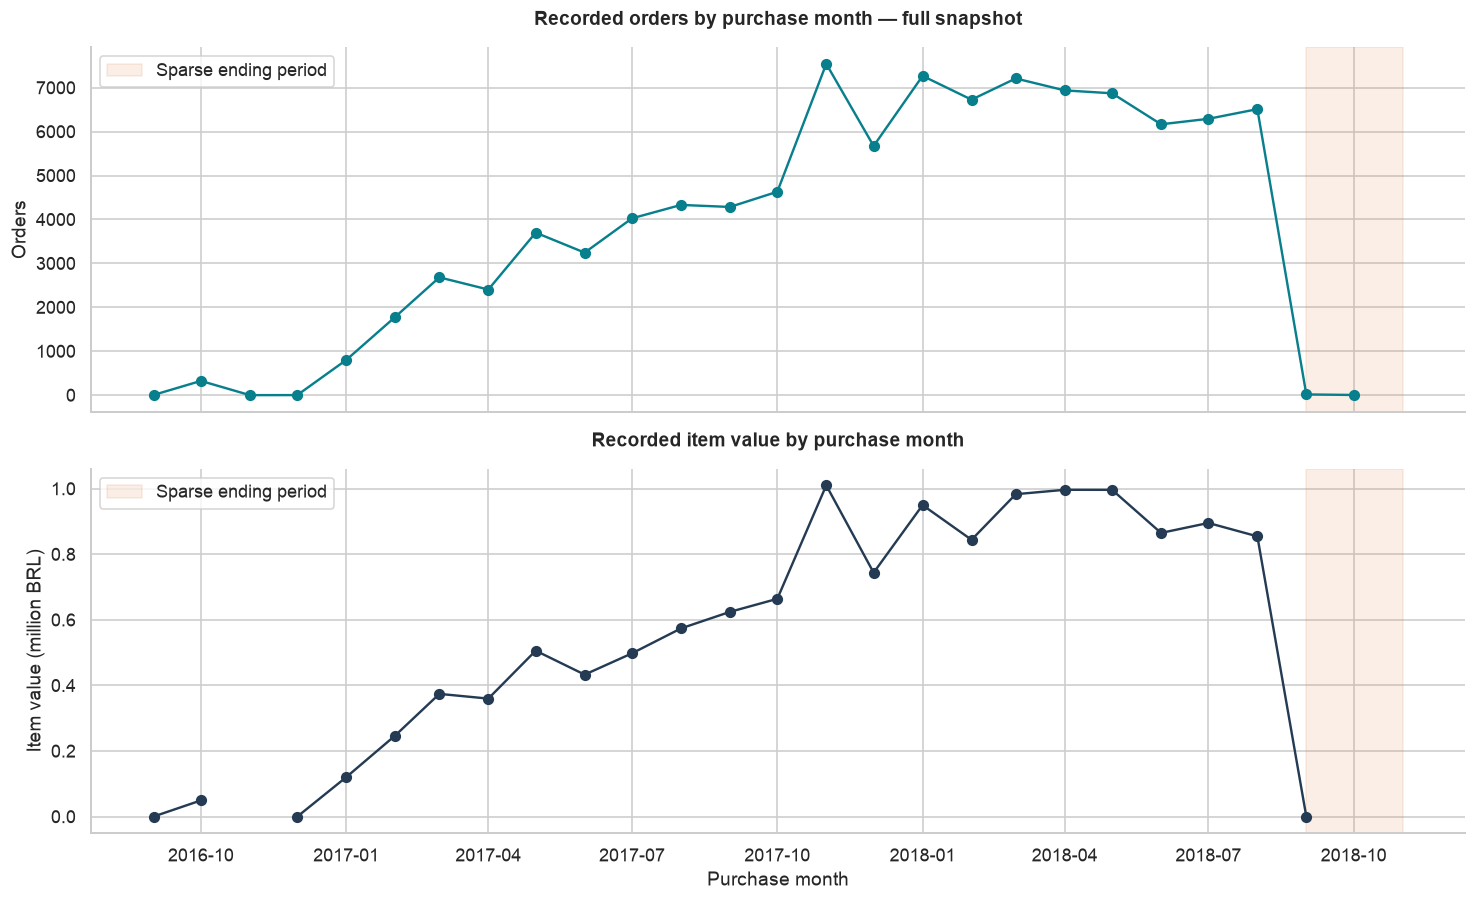

Purchase month,orders,item_value
2016-09-01 00:00:00,4,267.36
2016-10-01 00:00:00,324,"49,507.66"
2016-11-01 00:00:00,0,nan
2016-12-01 00:00:00,1,10.90
2017-01-01 00:00:00,800,"120,312.87"
2017-02-01 00:00:00,"1,780","247,303.02"
2017-03-01 00:00:00,"2,682","374,344.30"
2017-04-01 00:00:00,"2,404","359,927.23"
2017-05-01 00:00:00,"3,700","506,071.14"
2017-06-01 00:00:00,"3,245","433,038.60"


**Observed pattern:** the highest recorded month is **November 2017**, with **7,544 orders**. This describes the snapshot, not causal growth or complete market demand.

In [9]:
monthly=order_view.set_index('order_purchase_timestamp').resample('MS').agg(orders=('order_id','size'),item_value=('item_value',lambda s:s.sum(min_count=1)))
fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True)
axes[0].plot(monthly.index,monthly['orders'],marker='o',color=COLORS['teal'])
axes[0].set(title='Recorded orders by purchase month — full snapshot',ylabel='Orders')
axes[1].plot(monthly.index,monthly['item_value']/1e6,marker='o',color=COLORS['navy'])
axes[1].set(title='Recorded item value by purchase month',ylabel='Item value (million BRL)',xlabel='Purchase month')
for ax in axes:
    ax.axvspan(pd.Timestamp('2018-09-01'),pd.Timestamp('2018-11-01'),alpha=.12,color=COLORS['orange'],label='Sparse ending period')
    ax.legend(loc='upper left')
plt.tight_layout();plt.show()
table(monthly.reset_index().rename(columns={'order_purchase_timestamp':'Purchase month'}))
peak=monthly['orders'].idxmax()
note(f"**Observed pattern:** the highest recorded month is **{peak:%B %Y}**, with **{monthly.loc[peak,'orders']:,.0f} orders**. This describes the snapshot, not causal growth or complete market demand.")


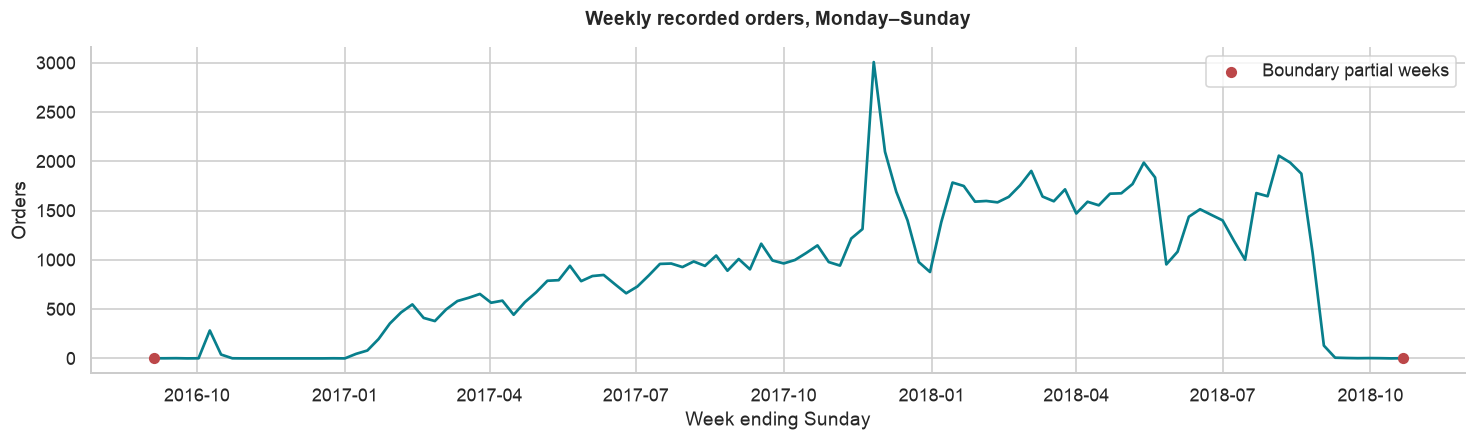

**Coverage:** 112 calendar weeks are represented, including 11 zero-order weeks. Boundary partial weeks are marked; no partial-week growth rate or forecast is calculated.

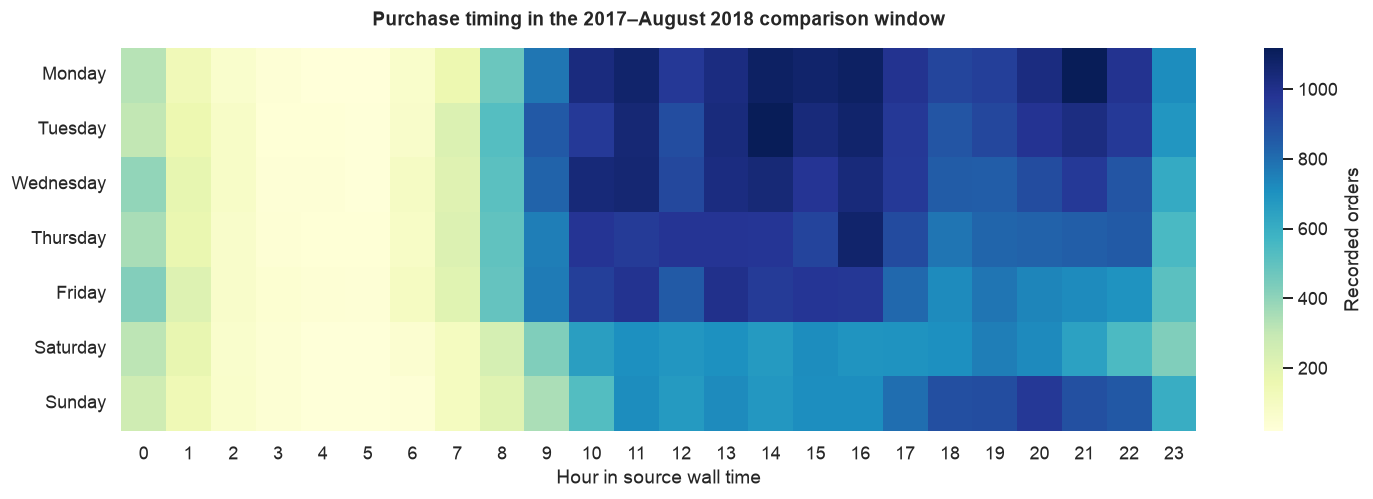

The heatmap shows counts, not rates per available weekday-hour. The source timezone is unknown, so hour-of-day is not converted to another timezone.

In [10]:
weekly=order_view.set_index('order_purchase_timestamp').resample('W-SUN').size()
first_day=order_view['order_purchase_timestamp'].min().normalize()
last_day=order_view['order_purchase_timestamp'].max().normalize()
week_start=weekly.index-pd.Timedelta(days=6)
complete_calendar=(week_start>=first_day)&(weekly.index<=last_day)
fig,ax=plt.subplots(figsize=(13,4))
ax.plot(weekly.index,weekly.values,color=COLORS['teal'],linewidth=1.7)
ax.scatter(weekly.index[~complete_calendar],weekly.values[~complete_calendar],color=COLORS['red'],label='Boundary partial weeks',zorder=4)
ax.set(title='Weekly recorded orders, Monday–Sunday',xlabel='Week ending Sunday',ylabel='Orders')
ax.legend();plt.tight_layout();plt.show()
note(f"**Coverage:** {len(weekly)} calendar weeks are represented, including {int(weekly.eq(0).sum())} zero-order weeks. Boundary partial weeks are marked; no partial-week growth rate or forecast is calculated.")

calendar=order_view.loc[order_view['order_purchase_timestamp'].ge('2017-01-01') & order_view['order_purchase_timestamp'].lt('2018-09-01'),'order_purchase_timestamp']
heat=pd.crosstab(calendar.dt.dayofweek,calendar.dt.hour).reindex(index=range(7),columns=range(24),fill_value=0)
heat.index=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
fig,ax=plt.subplots(figsize=(13,4.5))
sns.heatmap(heat,cmap='YlGnBu',ax=ax,cbar_kws={'label':'Recorded orders'})
ax.set(title='Purchase timing in the 2017–August 2018 comparison window',xlabel='Hour in source wall time',ylabel='')
plt.tight_layout();plt.show()
note('The heatmap shows counts, not rates per available weekday-hour. The source timezone is unknown, so hour-of-day is not converted to another timezone.')


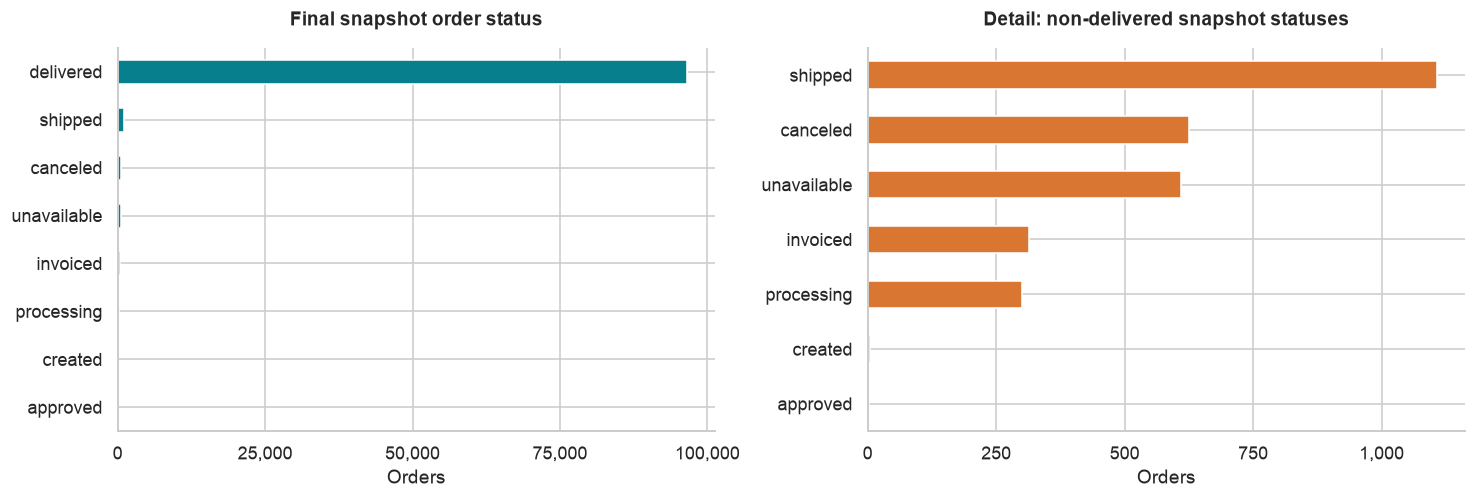

Status,Orders,Share_pct
delivered,"96,478",97.02
shipped,"1,107",1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


**Interpretation:** status is a final snapshot label. The dataset does not provide cancellation times or a full status history, so this chart is not an operational transition funnel.

In [11]:
status=orders['order_status'].value_counts()
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
horizontal_bars(status,'Final snapshot order status','Orders',ax=axes[0])
horizontal_bars(status.drop('delivered',errors='ignore'),'Detail: non-delivered snapshot statuses','Orders',color=COLORS['orange'],ax=axes[1])
plt.tight_layout();plt.show()
table(status.rename_axis('Status').reset_index(name='Orders').assign(Share_pct=lambda x:100*x['Orders']/len(orders)))
note('**Interpretation:** status is a final snapshot label. The dataset does not provide cancellation times or a full status history, so this chart is not an operational transition funnel.')


## 6. Basket value and freight

**Questions:** How varied are order values? How large is the freight charge relative to item value?

Every positive observed value is retained. Logarithmic axes display long tails; they do not delete expensive orders. Orders without item rows do not enter item-value distributions, and their count is reported. Freight share means freight / (item value + freight), not carrier cost or margin.


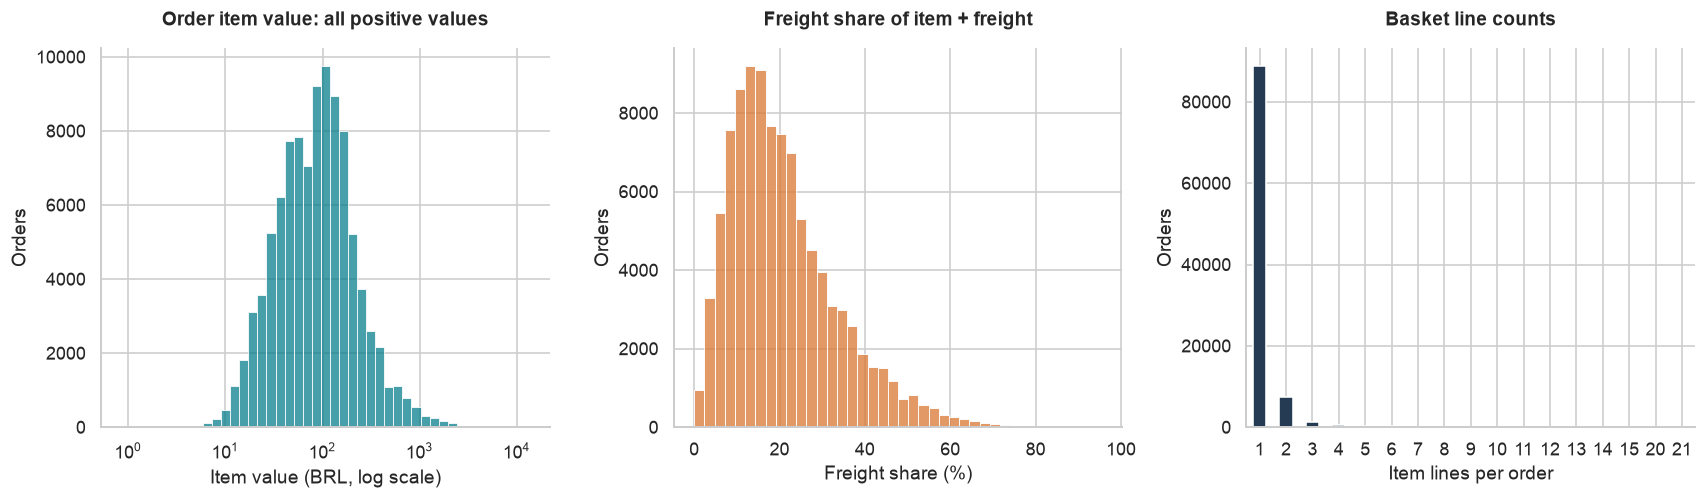

Statistic,item_value,freight_value,item_count,freight_share_pct
count,"98,666.00","98,666.00","98,666.00","98,666.00"
mean,137.75,22.82,1.14,20.88
std,210.65,21.65,0.54,12.57
min,0.85,0.00,1.00,0.00
50%,86.90,17.17,1.00,18.33
90%,269.90,39.50,1.00,38.37
95%,399.90,54.96,2.00,45.63
99%,998.90,104.98,3.00,59.38
max,"13,440.00","1,794.96",21.00,95.55


**Coverage:** 98,666 orders have item rows; 775 do not. Median item order value is **BRL 86.90**, versus mean **BRL 137.75**. This difference indicates a right-skewed distribution; large orders remain in all totals.

In [12]:
baskets=order_view.loc[order_view['item_value'].notna()].copy()
baskets['freight_share_pct']=100*baskets['freight_value']/(baskets['item_value']+baskets['freight_value'])
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
sns.histplot(baskets['item_value'],bins=45,log_scale=True,ax=axes[0],color=COLORS['teal'])
axes[0].set(title='Order item value: all positive values',xlabel='Item value (BRL, log scale)',ylabel='Orders')
sns.histplot(baskets['freight_share_pct'],bins=40,ax=axes[1],color=COLORS['orange'])
axes[1].set(title='Freight share of item + freight',xlabel='Freight share (%)',ylabel='Orders')
baskets['item_count'].value_counts().sort_index().plot.bar(ax=axes[2],color=COLORS['navy'],rot=0)
axes[2].set(title='Basket line counts',xlabel='Item lines per order',ylabel='Orders')
plt.tight_layout();plt.show()
table(baskets[['item_value','freight_value','item_count','freight_share_pct']].describe(percentiles=[.5,.9,.95,.99]).reset_index(names='Statistic'))
note(f"**Coverage:** {len(baskets):,} orders have item rows; {len(order_view)-len(baskets):,} do not. Median item order value is **BRL {baskets['item_value'].median():,.2f}**, versus mean **BRL {baskets['item_value'].mean():,.2f}**. This difference indicates a right-skewed distribution; large orders remain in all totals.")


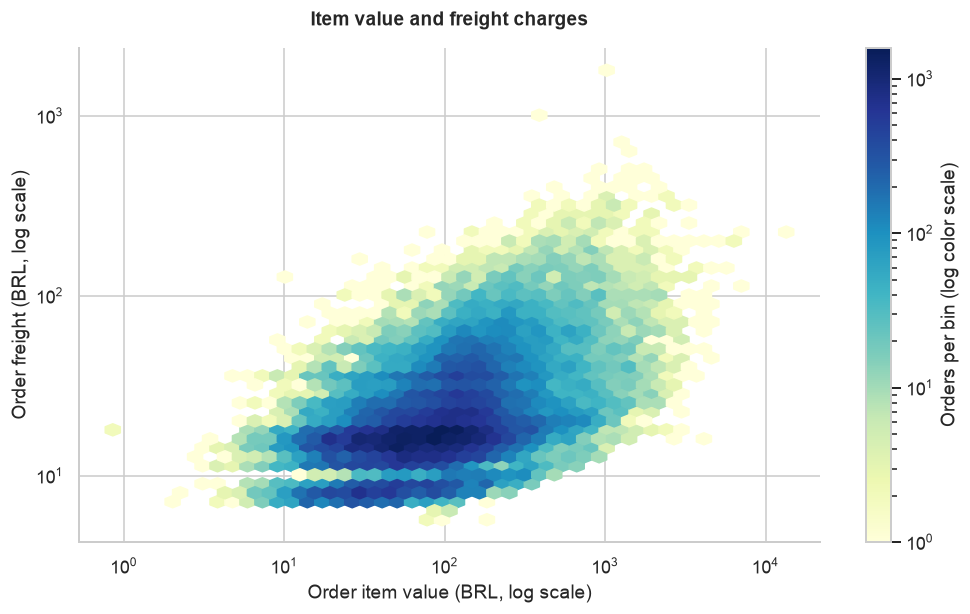

The log–log chart includes 98,328 orders with positive freight. 338 zero-freight orders are excluded **only from this log-axis plot**, not from totals. Association does not identify shipping-cost drivers.

In [13]:
positive_freight=baskets.loc[baskets['freight_value'].gt(0)]
fig,ax=plt.subplots(figsize=(9,5.5))
h=ax.hexbin(positive_freight['item_value'],positive_freight['freight_value'],xscale='log',yscale='log',gridsize=45,mincnt=1,bins='log',cmap='YlGnBu')
fig.colorbar(h,ax=ax,label='Orders per bin (log color scale)')
ax.set(title='Item value and freight charges',xlabel='Order item value (BRL, log scale)',ylabel='Order freight (BRL, log scale)')
plt.tight_layout();plt.show()
note(f"The log–log chart includes {len(positive_freight):,} orders with positive freight. {int(baskets['freight_value'].eq(0).sum()):,} zero-freight orders are excluded **only from this log-axis plot**, not from totals. Association does not identify shipping-cost drivers.")


## 7. Delivery experience

**Questions:** How long do observed deliveries take? How often do they exceed the promised calendar date? Where are durations inconsistent?

Primary rule: late if `delivery calendar date > estimated delivery calendar date`. Because estimates are dates at midnight, comparing timestamps instead can classify same-day deliveries as late. Both results are displayed. Orders without valid observed delivery are unknown, not on time.


Definition,Eligible deliveries,Late deliveries,Late rate %
After promised calendar day,"96,476","6,535",6.77
After exact estimated timestamp,"96,476","7,827",8.11


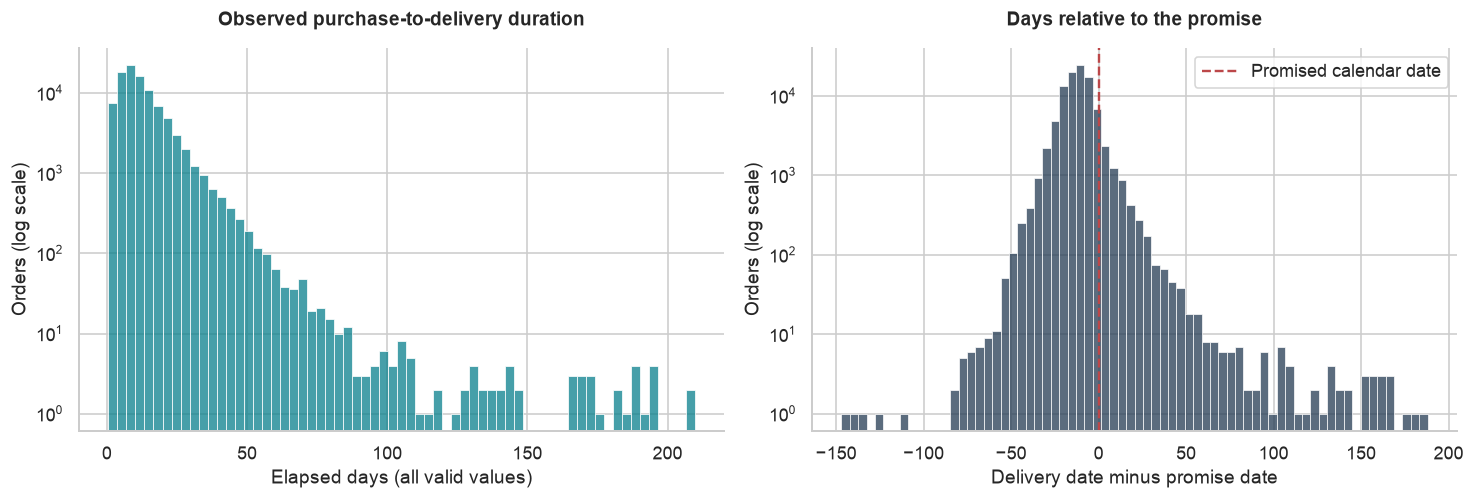

**Observed delivery:** median **10.2 days**, 90th percentile **23.1 days**. Calendar-day lateness is **6.77%**; exact-timestamp lateness is **8.11%**. The denominator is 96,476 observed deliveries; 2,965 other orders have no eligible delivery label.

In [14]:
deliveries=order_view.loc[valid_delivery].copy()
exact_late=deliveries['order_delivered_customer_date']>deliveries['order_estimated_delivery_date']
calendar_late=deliveries['late_calendar'].astype(bool)
late_comparison=pd.DataFrame({'Definition':['After promised calendar day','After exact estimated timestamp'],
                             'Eligible deliveries':[len(deliveries)]*2,'Late deliveries':[int(calendar_late.sum()),int(exact_late.sum())],
                             'Late rate %':[100*calendar_late.mean(),100*exact_late.mean()]})
table(late_comparison)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.histplot(deliveries['delivery_days'],bins=65,ax=axes[0],color=COLORS['teal'])
axes[0].set_yscale('log');axes[0].set(title='Observed purchase-to-delivery duration',xlabel='Elapsed days (all valid values)',ylabel='Orders (log scale)')
sns.histplot(deliveries['delay_calendar_days'],bins=70,ax=axes[1],color=COLORS['navy'])
axes[1].axvline(0,color=COLORS['red'],linestyle='--',label='Promised calendar date')
axes[1].set_yscale('log');axes[1].set(title='Days relative to the promise',xlabel='Delivery date minus promise date',ylabel='Orders (log scale)');axes[1].legend()
plt.tight_layout();plt.show()
note(f"**Observed delivery:** median **{deliveries['delivery_days'].median():.1f} days**, 90th percentile **{deliveries['delivery_days'].quantile(.9):.1f} days**. Calendar-day lateness is **{100*calendar_late.mean():.2f}%**; exact-timestamp lateness is **{100*exact_late.mean():.2f}%**. The denominator is {len(deliveries):,} observed deliveries; {len(order_view)-len(deliveries):,} other orders have no eligible delivery label.")


Segment,Eligible,Missing endpoint,Negative interval,Median days,P90 days
Purchase → approval,"99,281",160,0,0.01,1.44
Approval → carrier,"96,285","1,797","1,359",1.85,6.03
Carrier → delivery,"96,452","2,966",23,7.10,18.90


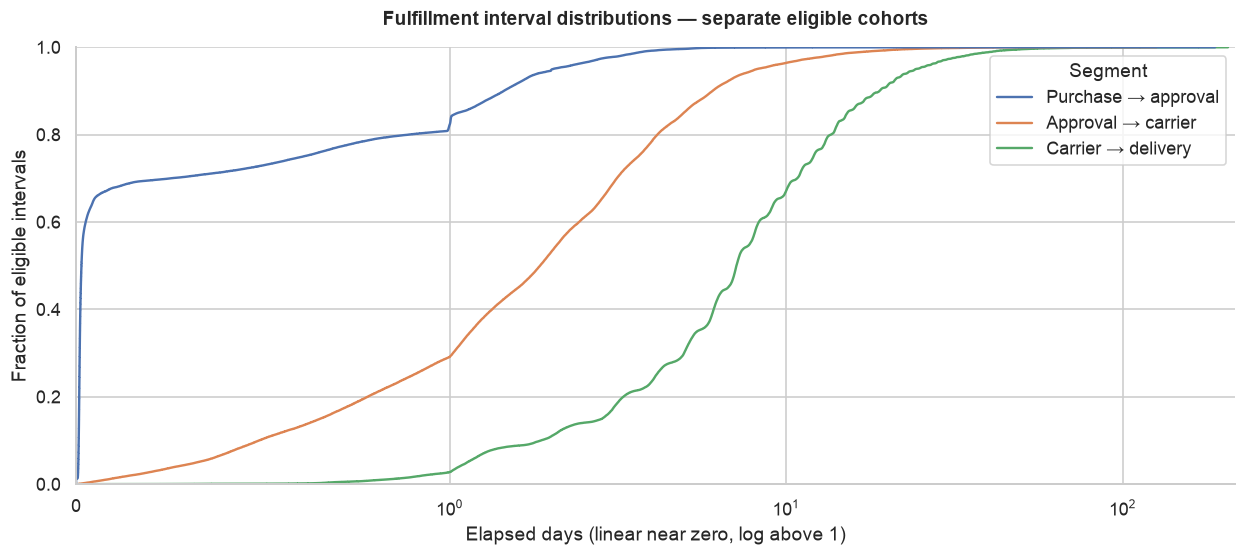

The segments have different eligible populations and are not a common complete-case funnel. Negative or missing intervals are excluded only from their segment. Approval and carrier events can be inconsistent even when the overall delivery duration is usable.

In [15]:
# Each segment gets its own mask. No global order deletion.
segments=[('Purchase → approval','order_purchase_timestamp','order_approved_at'),
          ('Approval → carrier','order_approved_at','order_delivered_carrier_date'),
          ('Carrier → delivery','order_delivered_carrier_date','order_delivered_customer_date')]
segment_rows=[];segment_values=[]
for label,start,end in segments:
    days=(orders[end]-orders[start]).dt.total_seconds()/86400
    ok=days.ge(0)
    segment_rows.append({'Segment':label,'Eligible':int(ok.sum()),'Missing endpoint':int(days.isna().sum()),
                         'Negative interval':int(days.lt(0).sum()),'Median days':days[ok].median(),'P90 days':days[ok].quantile(.9)})
    segment_values.append(pd.DataFrame({'Segment':label,'Elapsed days':days[ok]}))
table(pd.DataFrame(segment_rows))
fig,ax=plt.subplots(figsize=(11,5))
sns.ecdfplot(data=pd.concat(segment_values),x='Elapsed days',hue='Segment',ax=ax)
ax.set_xscale('symlog',linthresh=1)
ax.set_xlim(left=0)
ax.set(title='Fulfillment interval distributions — separate eligible cohorts',xlabel='Elapsed days (linear near zero, log above 1)',ylabel='Fraction of eligible intervals')
plt.tight_layout();plt.show()
note('The segments have different eligible populations and are not a common complete-case funnel. Negative or missing intervals are excluded only from their segment. Approval and carrier events can be inconsistent even when the overall delivery duration is usable.')


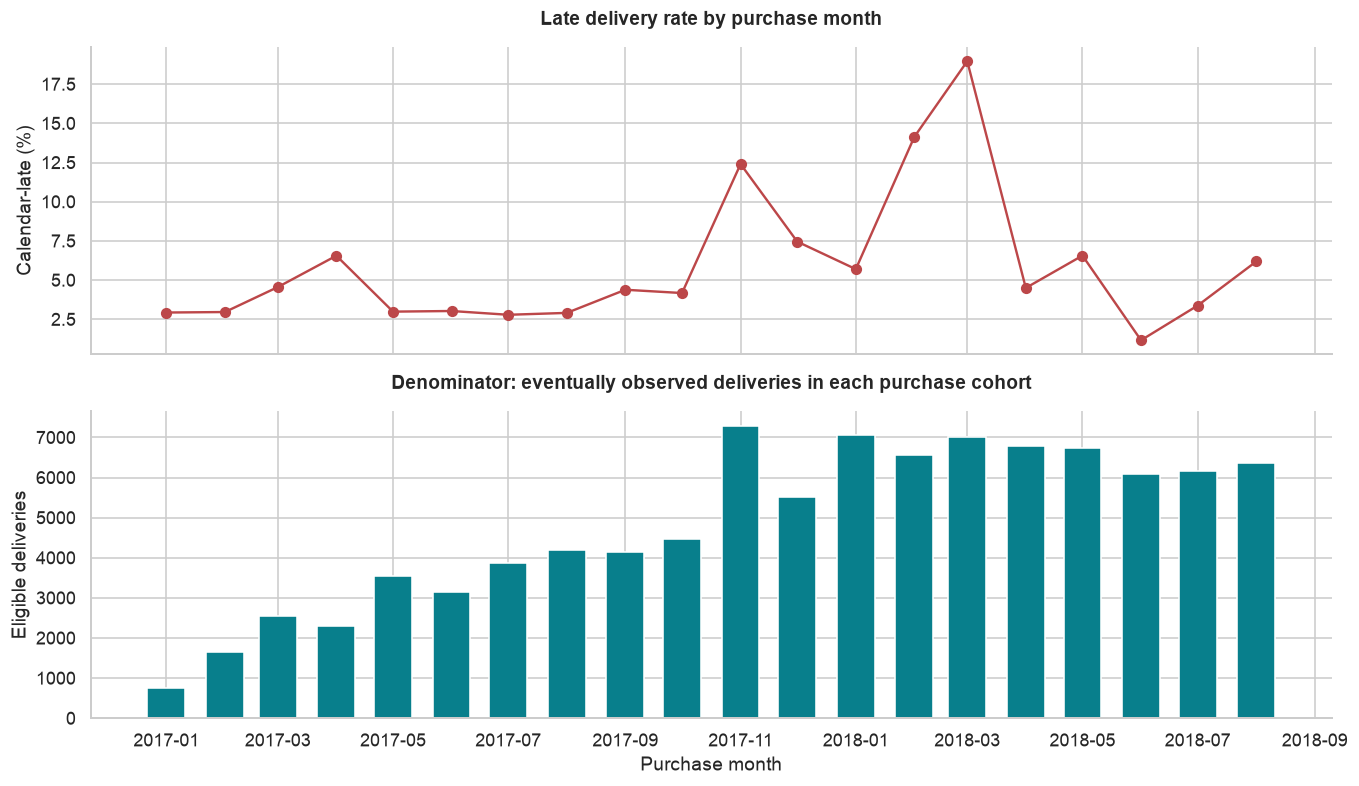

This is a **retrospective purchase-cohort** comparison using later observed deliveries. It is not what was known during that purchase month. Rates near the snapshot boundary may be affected by unobserved deliveries.

In [16]:
monthly_delivery=deliveries.assign(month=deliveries['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()).groupby('month').agg(
    deliveries=('order_id','size'),late=('late_calendar','sum'),median_days=('delivery_days','median'))
monthly_delivery['late_pct']=100*monthly_delivery['late']/monthly_delivery['deliveries']
plot_months=monthly_delivery.loc['2017-01-01':'2018-08-01']
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
axes[0].plot(plot_months.index,plot_months['late_pct'],marker='o',color=COLORS['red'])
axes[0].set(title='Late delivery rate by purchase month',ylabel='Calendar-late (%)')
axes[1].bar(plot_months.index,plot_months['deliveries'],width=20,color=COLORS['teal'])
axes[1].set(title='Denominator: eventually observed deliveries in each purchase cohort',ylabel='Eligible deliveries',xlabel='Purchase month')
plt.tight_layout();plt.show()
note('This is a **retrospective purchase-cohort** comparison using later observed deliveries. It is not what was known during that purchase month. Rates near the snapshot boundary may be affected by unobserved deliveries.')


## 8. Reviews and delivery relationships

**Questions:** What scores are recorded? How do first valid review scores differ by delivery experience? When do answers arrive?

Use raw review rows for the raw distribution; use one first valid answer per order for order-level associations. Negative means score 1 or 2. A missing answer is not a positive score. Optional text is summarized by presence only; this notebook does not display raw customer comments or infer sentiment.


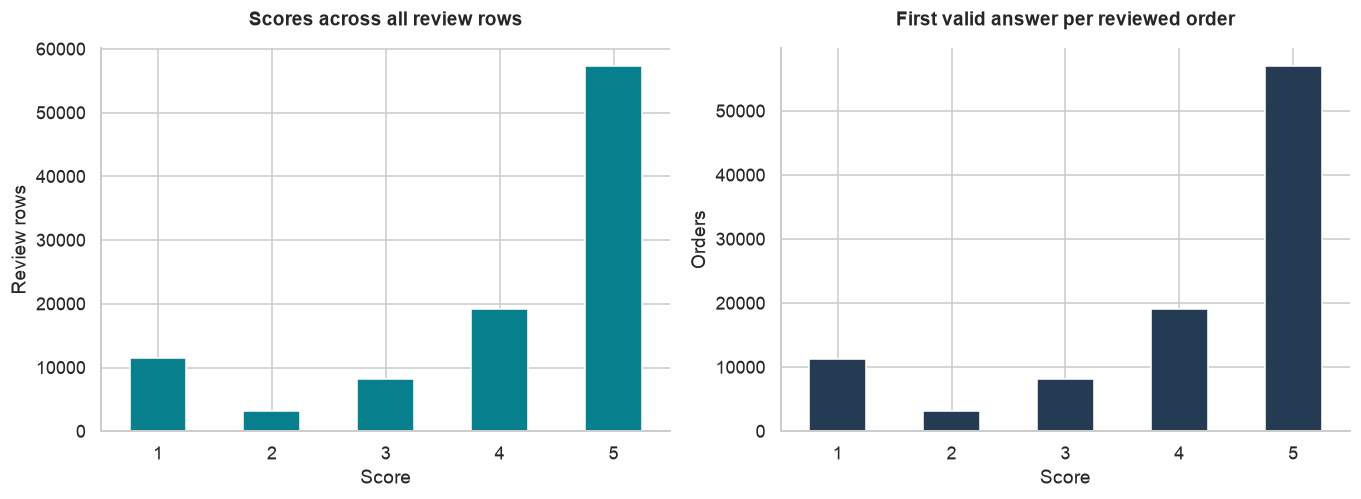

**Different grains:** 99,224 review rows versus 98,613 orders with a valid first answer. The latter negative-score rate is **14.64%**. Invalid pre-purchase answers are not used in this order-level measure; all raw review rows remain in the left chart.

Field,Review rows,Share %
Title present,"11,568",11.66
Message present,"40,977",41.30


In [17]:
raw_scores=reviews['review_score'].value_counts().reindex(range(1,6),fill_value=0)
first_scores=first_review['review_score'].value_counts().reindex(range(1,6),fill_value=0)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
raw_scores.plot.bar(ax=axes[0],color=COLORS['teal'],rot=0);axes[0].set(title='Scores across all review rows',xlabel='Score',ylabel='Review rows')
first_scores.plot.bar(ax=axes[1],color=COLORS['navy'],rot=0);axes[1].set(title='First valid answer per reviewed order',xlabel='Score',ylabel='Orders')
plt.tight_layout();plt.show()
note(f"**Different grains:** {len(reviews):,} review rows versus {len(first_review):,} orders with a valid first answer. The latter negative-score rate is **{100*first_review['review_score'].le(2).mean():.2f}%**. Invalid pre-purchase answers are not used in this order-level measure; all raw review rows remain in the left chart.")
table(pd.DataFrame({'Field':['Title present','Message present'],
                    'Review rows':[int(reviews['review_comment_title'].notna().sum()),int(reviews['review_comment_message'].notna().sum())],
                    'Share %':[100*reviews['review_comment_title'].notna().mean(),100*reviews['review_comment_message'].notna().mean()]}))


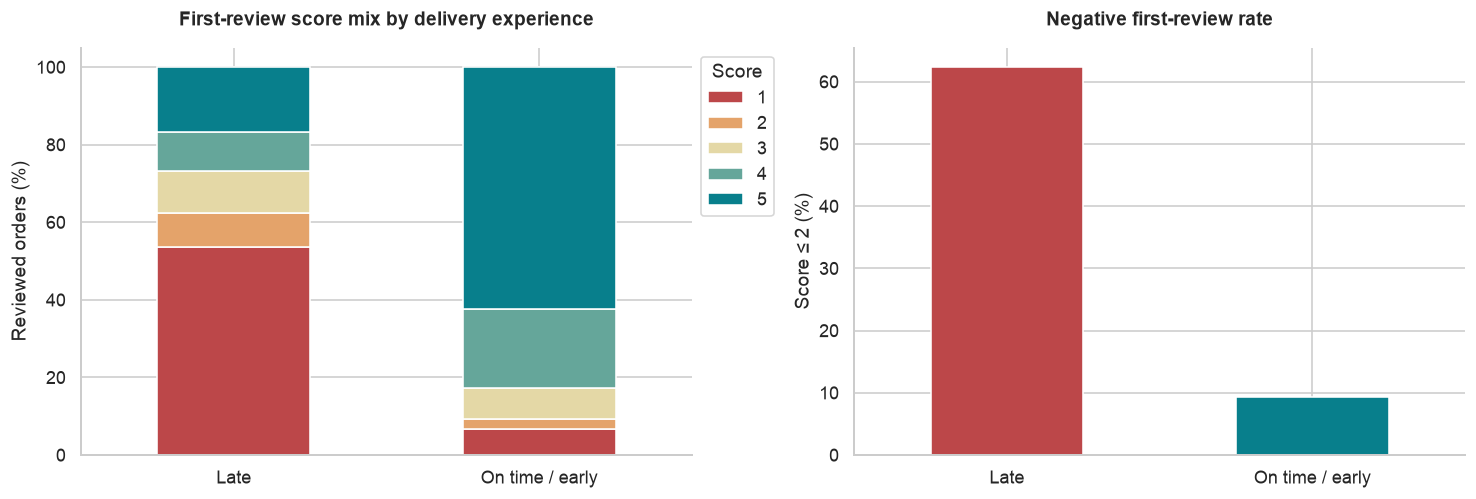

Delivery experience,reviewed_orders,negative,negative_pct
Late,"6,382","3,979",62.35
On time / early,"89,445","8,284",9.26


**Interpretation:** this is an association among orders with both observed delivery and a valid answer. Some reviews were submitted before delivery. The chart cannot prove that delay caused a low score or represent customers who did not respond.

In [18]:
review_delivery=order_view.loc[valid_delivery & order_view['review_score'].notna()].copy()
review_delivery['Delivery experience']=np.where(review_delivery['late_calendar'].astype(bool),'Late','On time / early')
review_delivery['Negative']=review_delivery['review_score'].le(2)
score_mix=pd.crosstab(review_delivery['Delivery experience'],review_delivery['review_score'],normalize='index').reindex(columns=range(1,6),fill_value=0)*100
negative_by_delivery=review_delivery.groupby('Delivery experience').agg(reviewed_orders=('order_id','size'),negative=('Negative','sum'))
negative_by_delivery['negative_pct']=100*negative_by_delivery['negative']/negative_by_delivery['reviewed_orders']
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
score_mix.plot.bar(stacked=True,ax=axes[0],color=['#BC4749','#E4A36A','#E4D8A6','#65A69A','#087F8C'],rot=0)
axes[0].set(title='First-review score mix by delivery experience',xlabel='',ylabel='Reviewed orders (%)');axes[0].legend(title='Score',bbox_to_anchor=(1,1),loc='upper left')
negative_by_delivery['negative_pct'].plot.bar(ax=axes[1],color=[COLORS['red'],COLORS['teal']],rot=0)
axes[1].set(title='Negative first-review rate',xlabel='',ylabel='Score ≤ 2 (%)')
plt.tight_layout();plt.show()
table(negative_by_delivery.reset_index())
note('**Interpretation:** this is an association among orders with both observed delivery and a valid answer. Some reviews were submitted before delivery. The chart cannot prove that delay caused a low score or represent customers who did not respond.')


Timing,First valid answers
Before or at observed delivery,"4,763"
After observed delivery,"91,064"
No observed delivery,"2,786"


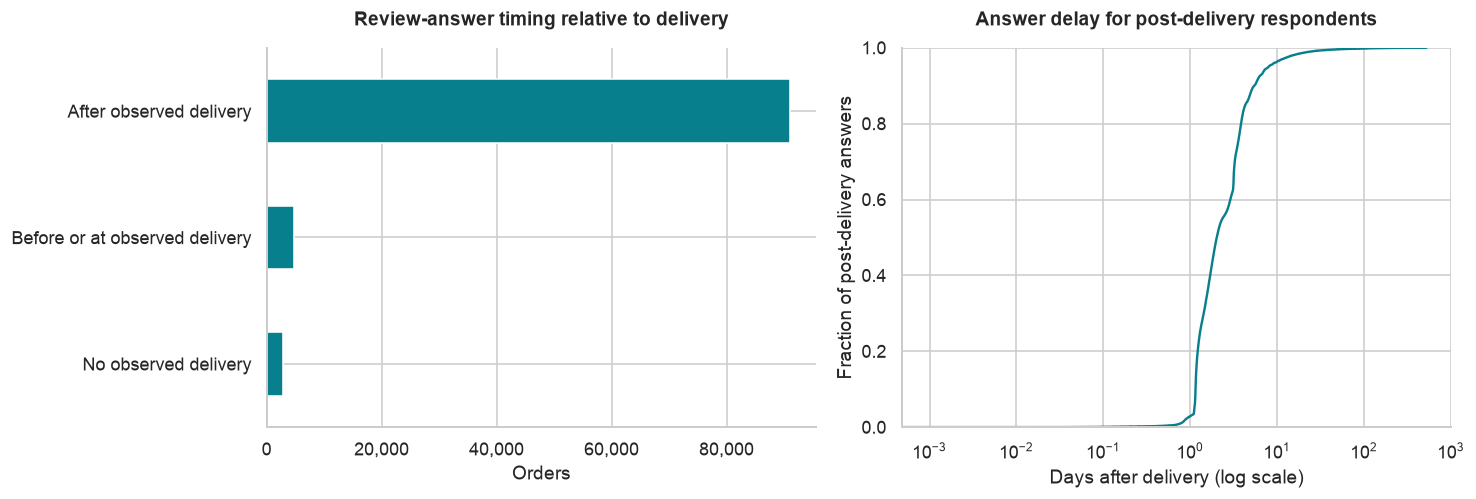

month,orders,reviewed,review_coverage_pct
2017-01-01 00:00:00,800,790,98.75
2017-02-01 00:00:00,"1,780","1,768",99.33
2017-03-01 00:00:00,"2,682","2,661",99.22
2017-04-01 00:00:00,"2,404","2,387",99.29
2017-05-01 00:00:00,"3,700","3,666",99.08
2017-06-01 00:00:00,"3,245","3,218",99.17
2017-07-01 00:00:00,"4,026","3,990",99.11
2017-08-01 00:00:00,"4,331","4,298",99.24
2017-09-01 00:00:00,"4,285","4,251",99.21
2017-10-01 00:00:00,"4,631","4,593",99.18


Review creation is survey creation metadata, not the time the score became known. Answer timestamp is used for timing. Coverage is retrospective and depends on observation length; no response is never imputed as a score.

In [19]:
answer_delay=(first_review['review_answer_timestamp']-first_review['order_delivered_customer_date']).dt.total_seconds()/86400
review_timing=pd.DataFrame({'Timing':['Before or at observed delivery','After observed delivery','No observed delivery'],
                           'First valid answers':[int(answer_delay.le(0).sum()),int(answer_delay.gt(0).sum()),int(answer_delay.isna().sum())]})
table(review_timing)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
horizontal_bars(review_timing.set_index('Timing')['First valid answers'],'Review-answer timing relative to delivery','Orders',ax=axes[0])
sns.ecdfplot(answer_delay[answer_delay>0],ax=axes[1],color=COLORS['teal'])
axes[1].set_xscale('log');axes[1].set(title='Answer delay for post-delivery respondents',xlabel='Days after delivery (log scale)',ylabel='Fraction of post-delivery answers')
plt.tight_layout();plt.show()
coverage=order_view.assign(month=order_view['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()).groupby('month').agg(
    orders=('order_id','size'),reviewed=('review_score','count'))
coverage['review_coverage_pct']=100*coverage['reviewed']/coverage['orders']
table(coverage.loc['2017-01-01':'2018-08-01'].reset_index())
note('Review creation is survey creation metadata, not the time the score became known. Answer timestamp is used for timing. Coverage is retrospective and depends on observation length; no response is never imputed as a score.')


## 9. Payments and reconciliation

**Questions:** How are payment records distributed across methods and installments? Do order payment totals reconcile to item value plus freight?

Payment types are payment-row categories; one order may use several methods. Payment records have no settlement timestamps. Values grouped by purchase month would not be cash-flow timing.


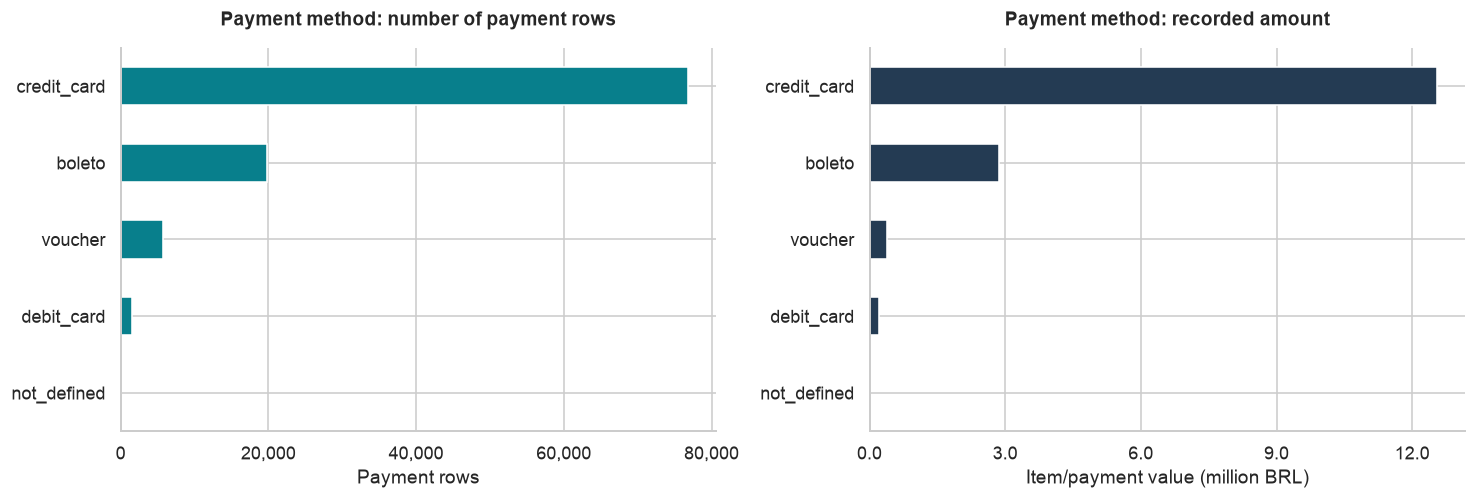

payment_type,payment_rows,orders,value
credit_card,"76,795","76,505","12,542,084.19"
boleto,"19,784","19,784","2,869,361.27"
voucher,"5,775","3,866","379,436.87"
debit_card,"1,529","1,528","217,989.79"
not_defined,3,3,0.00


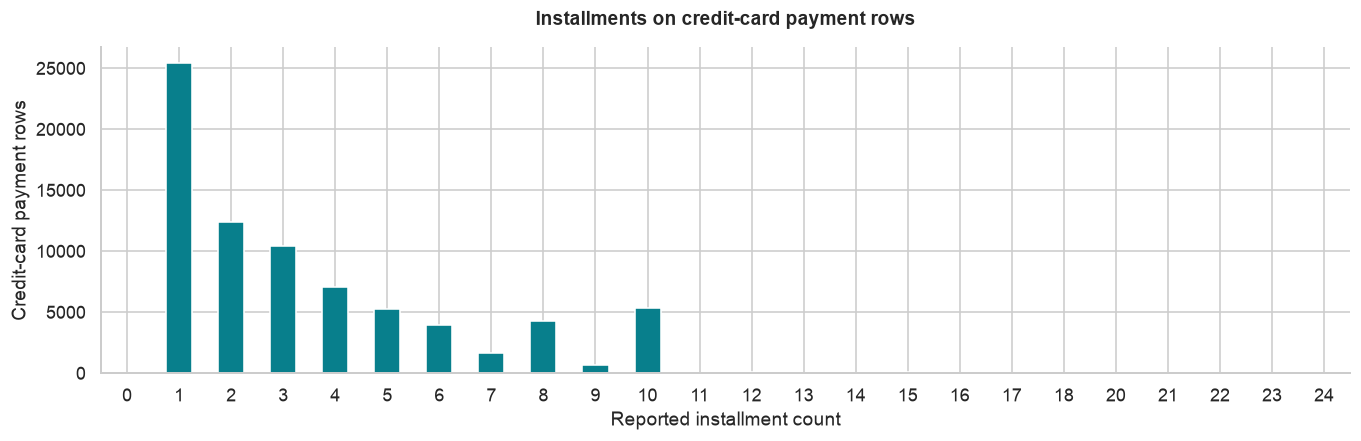

Orders counted by method are non-additive because an order may use multiple methods. Zero installment counts remain visible as source anomalies; they are not replaced with one.

In [20]:
payment_methods=payments.groupby('payment_type').agg(payment_rows=('order_id','size'),orders=('order_id','nunique'),value=('payment_value','sum')).sort_values('value',ascending=False)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
horizontal_bars(payment_methods['payment_rows'],'Payment method: number of payment rows','Payment rows',ax=axes[0])
horizontal_bars(payment_methods['value'],'Payment method: recorded amount','BRL',color=COLORS['navy'],ax=axes[1])
plt.tight_layout();plt.show();table(payment_methods.reset_index())
installments=payments.loc[payments['payment_type'].eq('credit_card'),'payment_installments'].value_counts().sort_index()
fig,ax=plt.subplots(figsize=(12,4))
installments.plot.bar(ax=ax,color=COLORS['teal'],rot=0)
ax.set(title='Installments on credit-card payment rows',xlabel='Reported installment count',ylabel='Credit-card payment rows')
plt.tight_layout();plt.show()
note('Orders counted by method are non-additive because an order may use multiple methods. Zero installment counts remain visible as source anomalies; they are not replaced with one.')


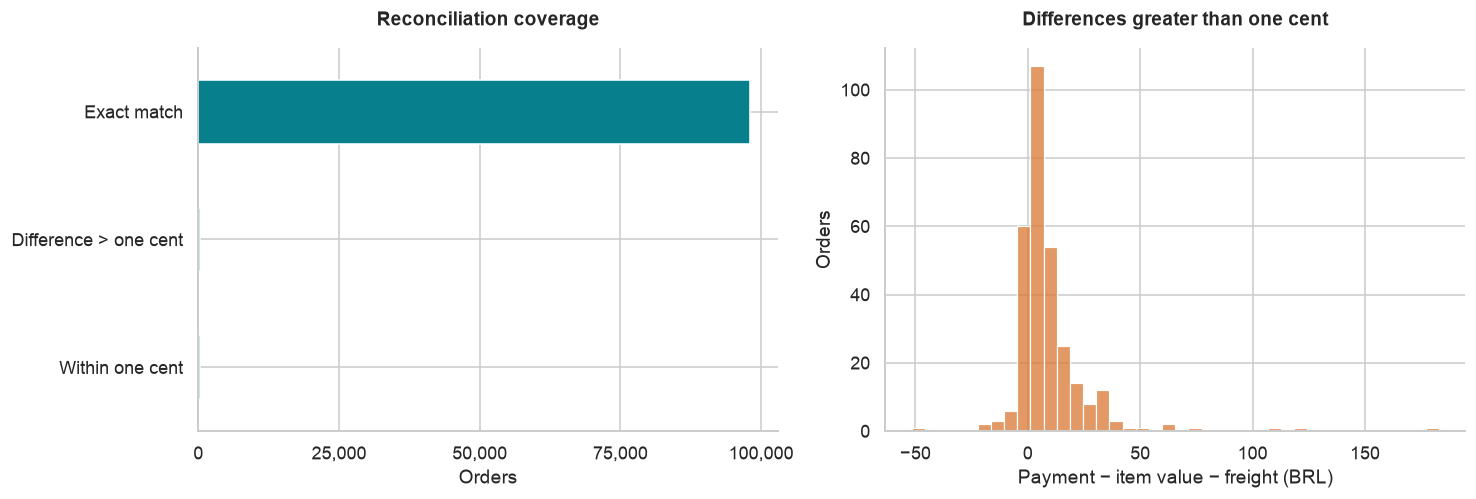

Measure,Value
Orders with both sides,"98,665.00"
Orders without item rows,775.00
Orders without payment rows,1.00
Difference > one cent,303.00
Net difference across matched orders (BRL),"2,870.39"


Differences are reported, not corrected. The source does not explain every discrepancy; refunds, discounts or settlement timing must not be invented as explanations. Missing sides are not treated as zero.

In [21]:
reconciliation=order_view.loc[order_view['item_value'].notna() & order_view['payment_value'].notna(),['order_id','item_value','freight_value','payment_value']].copy()
# Integer cents avoid binary floating-point ambiguity in monetary differences.
reconciliation['item_and_freight_cents']=np.rint((reconciliation['item_value']+reconciliation['freight_value'])*100).astype('int64')
reconciliation['payment_cents']=np.rint(reconciliation['payment_value']*100).astype('int64')
reconciliation['difference_brl']=(reconciliation['payment_cents']-reconciliation['item_and_freight_cents'])/100
reconciliation['Class']=np.select([reconciliation['difference_brl'].eq(0),reconciliation['difference_brl'].abs().le(.01)],['Exact match','Within one cent'],default='Difference > one cent')
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
horizontal_bars(reconciliation['Class'].value_counts(),'Reconciliation coverage','Orders',ax=axes[0])
different=reconciliation.loc[reconciliation['difference_brl'].abs().gt(.01),'difference_brl']
sns.histplot(different,bins=40,ax=axes[1],color=COLORS['orange'])
axes[1].set(title='Differences greater than one cent',xlabel='Payment − item value − freight (BRL)',ylabel='Orders')
plt.tight_layout();plt.show()
table(pd.DataFrame({'Measure':['Orders with both sides','Orders without item rows','Orders without payment rows','Difference > one cent','Net difference across matched orders (BRL)'],
                    'Value':[len(reconciliation),int(order_view['item_value'].isna().sum()),int(order_view['payment_value'].isna().sum()),len(different),reconciliation['difference_brl'].sum()]}))
note('Differences are reported, not corrected. The source does not explain every discrepancy; refunds, discounts or settlement timing must not be invented as explanations. Missing sides are not treated as zero.')


## 10. Products and categories

**Questions:** Which categories account for recorded item value and order volume? How concentrated is activity? How sparse is the long tail?

Category translations are optional lookups. Unmapped categories retain their Portuguese names in chart labels. Missing categories appear as an explicit display group. Item-value totals are additive across categories; category order counts are not, because a basket may contain multiple categories.


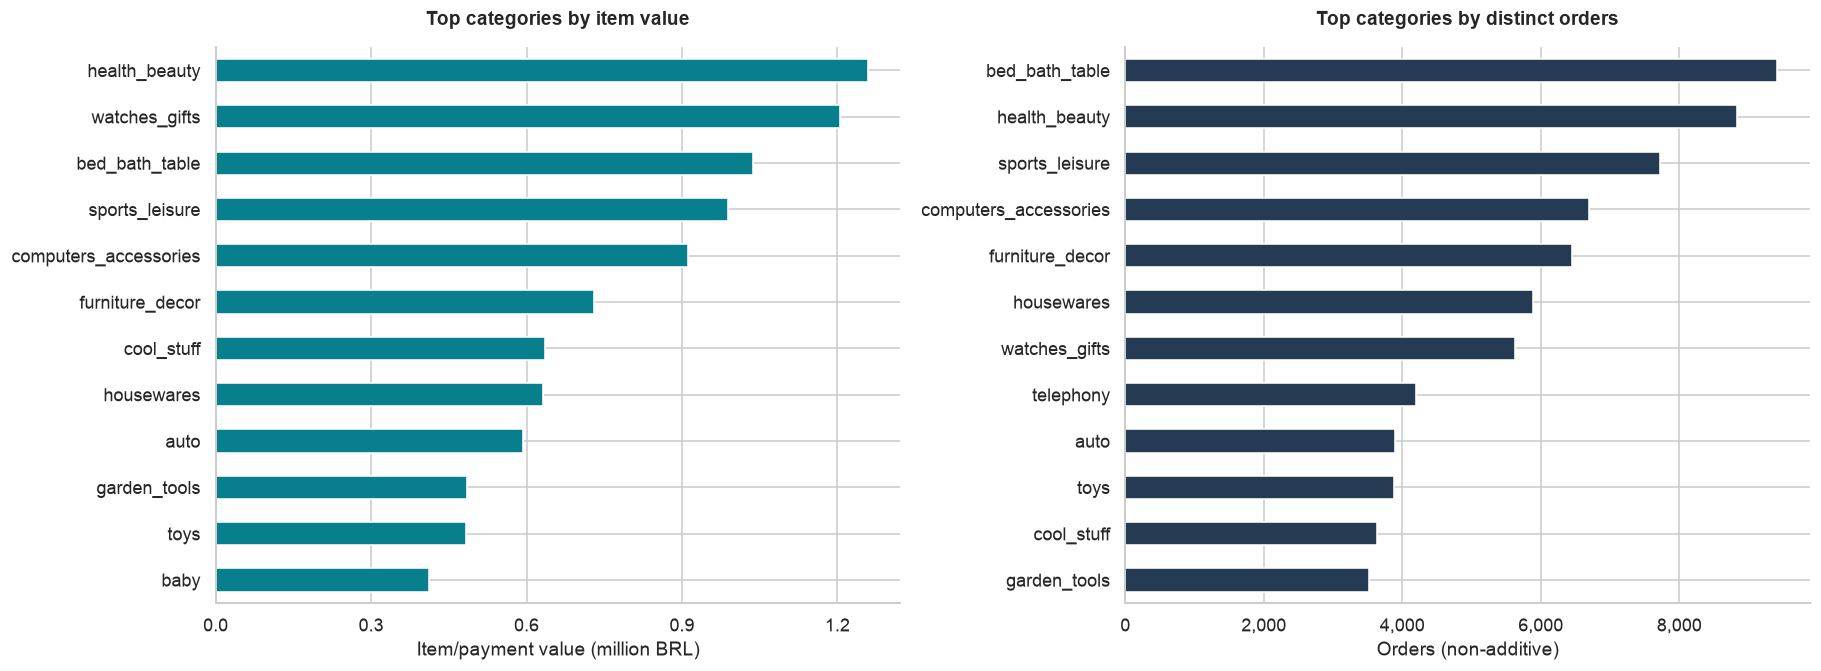

category_display,item_lines,orders,products,item_value,freight
health_beauty,"9,670","8,836","2,444","1,258,681.34","182,566.73"
watches_gifts,"5,991","5,624","1,329","1,205,005.68","100,535.93"
bed_bath_table,"11,115","9,417","3,029","1,036,988.68","204,693.04"
sports_leisure,"8,641","7,720","2,867","988,048.97","168,607.51"
computers_accessories,"7,827","6,689","1,639","911,954.32","147,318.08"
furniture_decor,"8,334","6,449","2,657","729,762.49","172,749.30"
cool_stuff,"3,796","3,632",789,"635,290.85","84,039.10"
housewares,"6,964","5,884","2,335","632,248.66","146,149.11"
auto,"4,235","3,897","1,900","592,720.11","92,664.21"
garden_tools,"4,347","3,518",753,"485,256.46","98,962.75"


The top 10 display categories account for **62.4%** of recorded item value. Unknown-category items remain in the total. Categories range from 2 to 9,417 observed orders; small groups should not be ranked by unstable rates.

In [22]:
product_lookup=products.merge(data['translation'],on='product_category_name',how='left',validate='many_to_one')
product_lookup['category_display']=product_lookup['product_category_name_english'].fillna(product_lookup['product_category_name']).fillna('Unknown category')
item_view=(items.merge(product_lookup,on='product_id',how='left',validate='many_to_one')
           .merge(orders[['order_id','order_purchase_timestamp']],on='order_id',how='left',validate='many_to_one'))
assert len(item_view)==len(items)
category_summary=item_view.groupby('category_display').agg(item_lines=('order_id','size'),orders=('order_id','nunique'),products=('product_id','nunique'),item_value=('price','sum'),freight=('freight_value','sum')).sort_values('item_value',ascending=False)
fig,axes=plt.subplots(1,2,figsize=(16,6))
horizontal_bars(category_summary.head(12)['item_value'],'Top categories by item value','BRL',ax=axes[0])
horizontal_bars(category_summary.sort_values('orders',ascending=False).head(12)['orders'],'Top categories by distinct orders','Orders (non-additive)',color=COLORS['navy'],ax=axes[1])
plt.tight_layout();plt.show()
table(category_summary.head(15).reset_index())
assert np.isclose(category_summary['item_value'].sum(),items['price'].sum())
note(f"The top 10 display categories account for **{100*category_summary.head(10)['item_value'].sum()/category_summary['item_value'].sum():.1f}%** of recorded item value. Unknown-category items remain in the total. Categories range from {category_summary['orders'].min():,} to {category_summary['orders'].max():,} observed orders; small groups should not be ranked by unstable rates.")


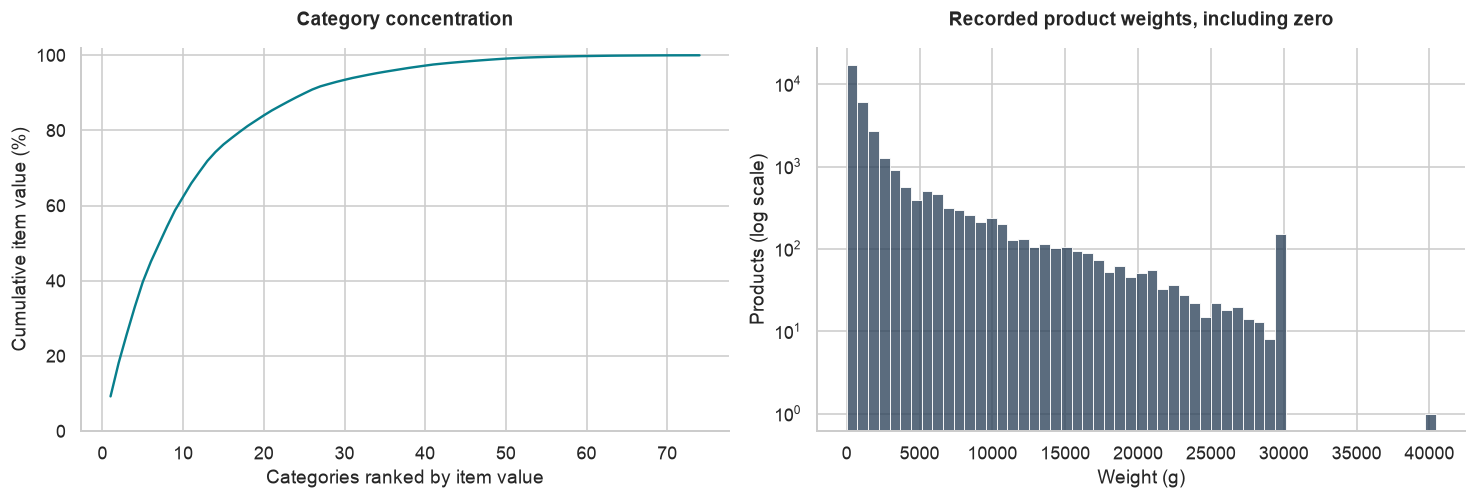

Statistic,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,"32,341.00","32,341.00","32,341.00","32,949.00","32,949.00","32,949.00","32,949.00"
mean,48.48,771.50,2.19,"2,276.47",30.82,16.94,23.20
std,10.25,635.12,1.74,"4,282.04",16.91,13.64,12.08
min,5.00,4.00,1.00,0.00,7.00,2.00,6.00
50%,51.00,595.00,1.00,700.00,25.00,13.00,20.00
90%,59.00,"1,578.00",5.00,"6,300.00",53.00,33.00,40.00
99%,63.00,"3,286.20",8.00,"22,538.00",100.00,69.00,63.00
max,76.00,"3,992.00",20.00,"40,425.00",105.00,105.00,118.00


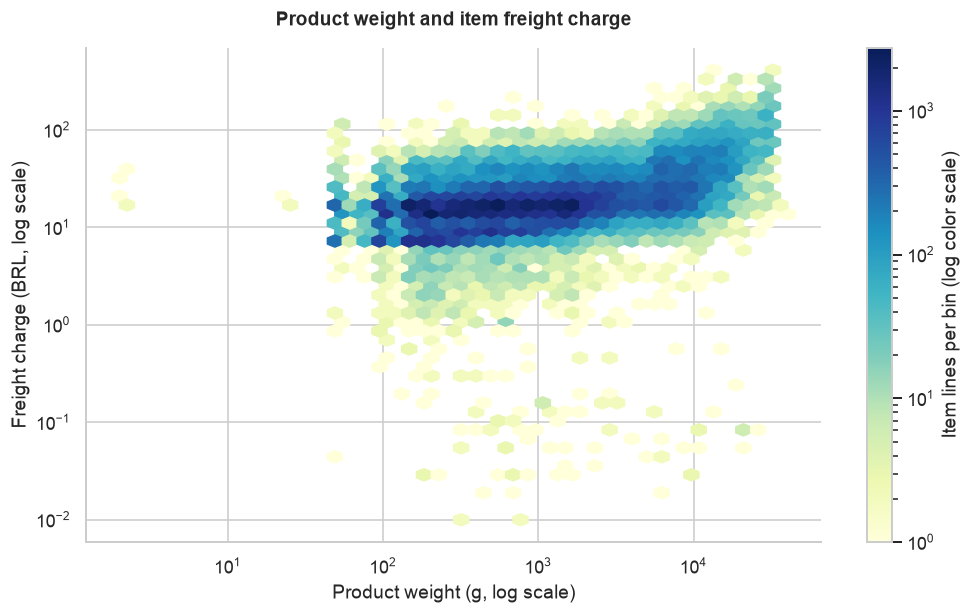

**Plot-specific eligibility:** 112,241/112,650 item lines have positive reported weight and freight. Other lines remain in all applicable totals. Product metadata are static snapshots; dimensions and weight alone cannot explain freight pricing. Original misspelled metadata names are preserved.

In [23]:
ordered_values=category_summary['item_value'].sort_values(ascending=False)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
axes[0].plot(np.arange(1,len(ordered_values)+1),100*ordered_values.cumsum()/ordered_values.sum(),color=COLORS['teal'])
axes[0].set(title='Category concentration',xlabel='Categories ranked by item value',ylabel='Cumulative item value (%)');axes[0].set_ylim(0,102)
sns.histplot(products['product_weight_g'].dropna(),bins=55,ax=axes[1],color=COLORS['navy'])
axes[1].set_yscale('log');axes[1].set(title='Recorded product weights, including zero',xlabel='Weight (g)',ylabel='Products (log scale)')
plt.tight_layout();plt.show()
product_numeric=['product_name_lenght','product_description_lenght','product_photos_qty','product_weight_g','product_length_cm','product_height_cm','product_width_cm']
table(products[product_numeric].describe(percentiles=[.5,.9,.99]).reset_index(names='Statistic'))
weight_plot=item_view.loc[item_view['product_weight_g'].gt(0) & item_view['freight_value'].gt(0)]
fig,ax=plt.subplots(figsize=(9,5.5))
h=ax.hexbin(weight_plot['product_weight_g'],weight_plot['freight_value'],xscale='log',yscale='log',gridsize=45,mincnt=1,bins='log',cmap='YlGnBu')
fig.colorbar(h,ax=ax,label='Item lines per bin (log color scale)')
ax.set(title='Product weight and item freight charge',xlabel='Product weight (g, log scale)',ylabel='Freight charge (BRL, log scale)')
plt.tight_layout();plt.show()
note(f"**Plot-specific eligibility:** {len(weight_plot):,}/{len(item_view):,} item lines have positive reported weight and freight. Other lines remain in all applicable totals. Product metadata are static snapshots; dimensions and weight alone cannot explain freight pricing. Original misspelled metadata names are preserved.")


## 11. Sellers

**Questions:** Is recorded sales value concentrated among sellers? How frequent are multi-seller orders?

Seller value uses each item line once. An order-level delivery outcome cannot identify which seller caused a delay, particularly for multi-seller baskets. IDs are not printed; seller concentration and state summaries are sufficient for this exploration.


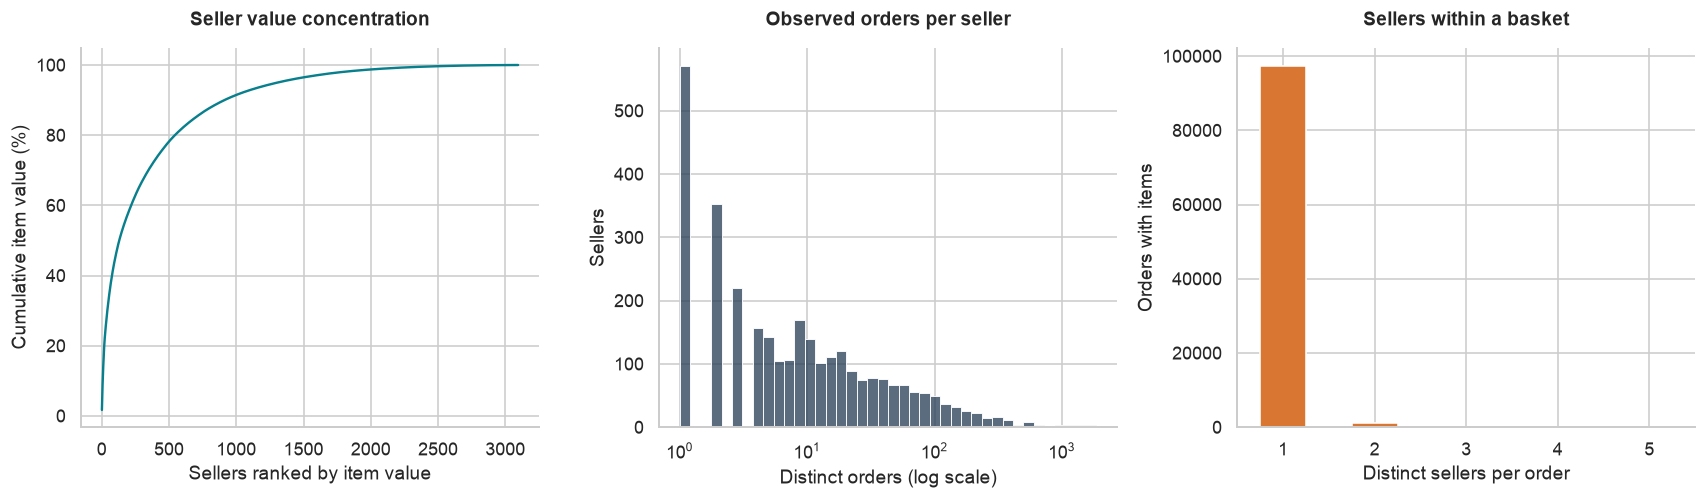

seller_state,sellers,item_value
SP,"1,849","8,753,396.21"
PR,349,"1,261,887.21"
MG,244,"1,011,564.74"
RJ,171,"843,984.22"
SC,190,"632,426.07"
RS,129,"378,559.54"
BA,19,"285,561.56"
DF,30,"97,749.48"
PE,9,"91,493.85"
GO,40,"66,399.21"


**Multi-seller orders:** 1,278. The top 10 sellers account for **13.1%** of recorded item value. Seller-level distinct order counts overlap and should not be summed as company order volume.

In [24]:
seller_activity=items.groupby('seller_id').agg(item_value=('price','sum'),item_lines=('order_id','size'),orders=('order_id','nunique')).sort_values('item_value',ascending=False)
seller_activity=seller_activity.merge(sellers[['seller_id','seller_state']],on='seller_id',how='left',validate='one_to_one')
ranked=seller_activity['item_value'].sort_values(ascending=False)
seller_counts=item_by_order['seller_count'].value_counts().sort_index()
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
axes[0].plot(np.arange(1,len(ranked)+1),100*ranked.cumsum()/ranked.sum(),color=COLORS['teal'])
axes[0].set(title='Seller value concentration',xlabel='Sellers ranked by item value',ylabel='Cumulative item value (%)')
sns.histplot(seller_activity['orders'],bins=40,log_scale=True,ax=axes[1],color=COLORS['navy'])
axes[1].set(title='Observed orders per seller',xlabel='Distinct orders (log scale)',ylabel='Sellers')
seller_counts.plot.bar(ax=axes[2],color=COLORS['orange'],rot=0)
axes[2].set(title='Sellers within a basket',xlabel='Distinct sellers per order',ylabel='Orders with items')
plt.tight_layout();plt.show()
table(seller_activity.groupby('seller_state').agg(sellers=('seller_id','size'),item_value=('item_value','sum')).sort_values('item_value',ascending=False).head(12).reset_index())
note(f"**Multi-seller orders:** {int(item_by_order['seller_count'].gt(1).sum()):,}. The top 10 sellers account for **{100*ranked.head(10).sum()/ranked.sum():.1f}%** of recorded item value. Seller-level distinct order counts overlap and should not be summed as company order volume.")


## 12. Customers and observed repeat behavior

**Questions:** How often does the same buyer appear more than once? What intervals separate their recorded purchases?

Use `customer_unique_id` for buyer history. The snapshot records activity on this platform only, with unequal observation time. One observed purchase does not imply permanent churn. No customer clustering, RFM segmentation, lifetime-value estimation or prediction is performed.


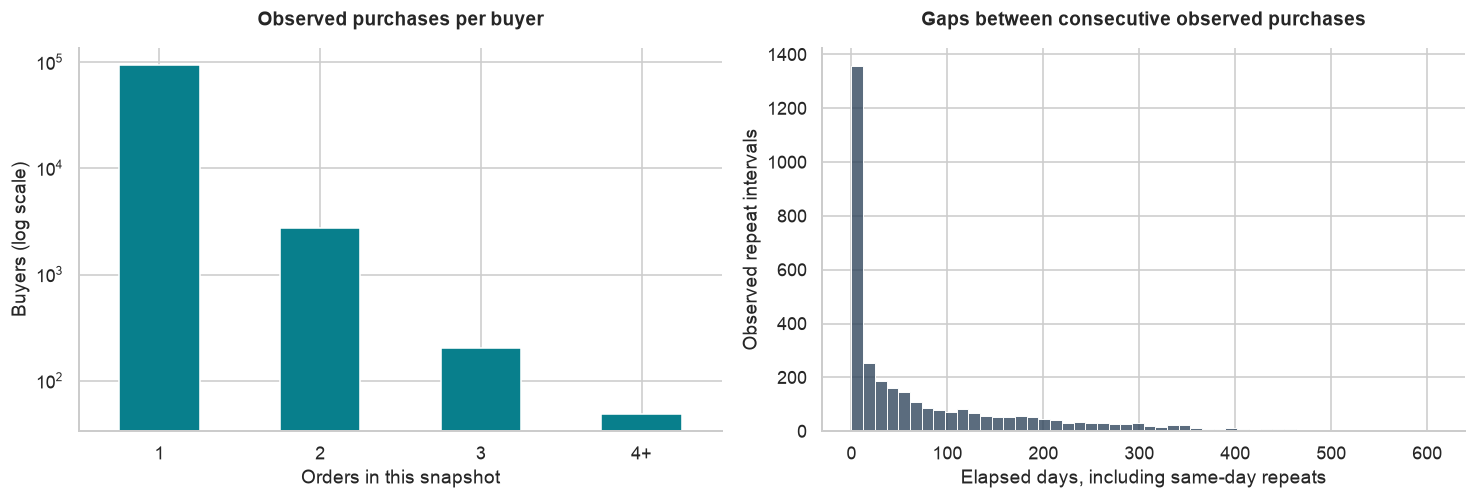

**Observed repeat share:** 2,997/96,096 buyers (**3.12%**) have more than one order. This is a snapshot statistic, not a fixed-window retention rate. Most observed buyers contribute a single order, limiting claims about loyalty or long-term behavior.

In [25]:
buyer_summary=order_view.groupby('customer_unique_id').agg(orders=('order_id','size'),item_value=('item_value',lambda s:s.sum(min_count=1)),first_purchase=('order_purchase_timestamp','min'),last_purchase=('order_purchase_timestamp','max'))
buyer_summary['frequency_group']=pd.cut(buyer_summary['orders'],bins=[0,1,2,3,np.inf],labels=['1','2','3','4+'])
frequency=buyer_summary['frequency_group'].value_counts(sort=False)
ordered_purchases=order_view.sort_values(['customer_unique_id','order_purchase_timestamp'])
gaps=ordered_purchases.groupby('customer_unique_id')['order_purchase_timestamp'].diff().dt.total_seconds()/86400
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
frequency.plot.bar(ax=axes[0],color=COLORS['teal'],rot=0)
axes[0].set_yscale('log');axes[0].set(title='Observed purchases per buyer',xlabel='Orders in this snapshot',ylabel='Buyers (log scale)')
sns.histplot(gaps.dropna(),bins=50,ax=axes[1],color=COLORS['navy'])
axes[1].set(title='Gaps between consecutive observed purchases',xlabel='Elapsed days, including same-day repeats',ylabel='Observed repeat intervals')
plt.tight_layout();plt.show()
repeat=int(buyer_summary['orders'].gt(1).sum())
note(f"**Observed repeat share:** {repeat:,}/{len(buyer_summary):,} buyers (**{100*repeat/len(buyer_summary):.2f}%**) have more than one order. This is a snapshot statistic, not a fixed-window retention rate. Most observed buyers contribute a single order, limiting claims about loyalty or long-term behavior.")


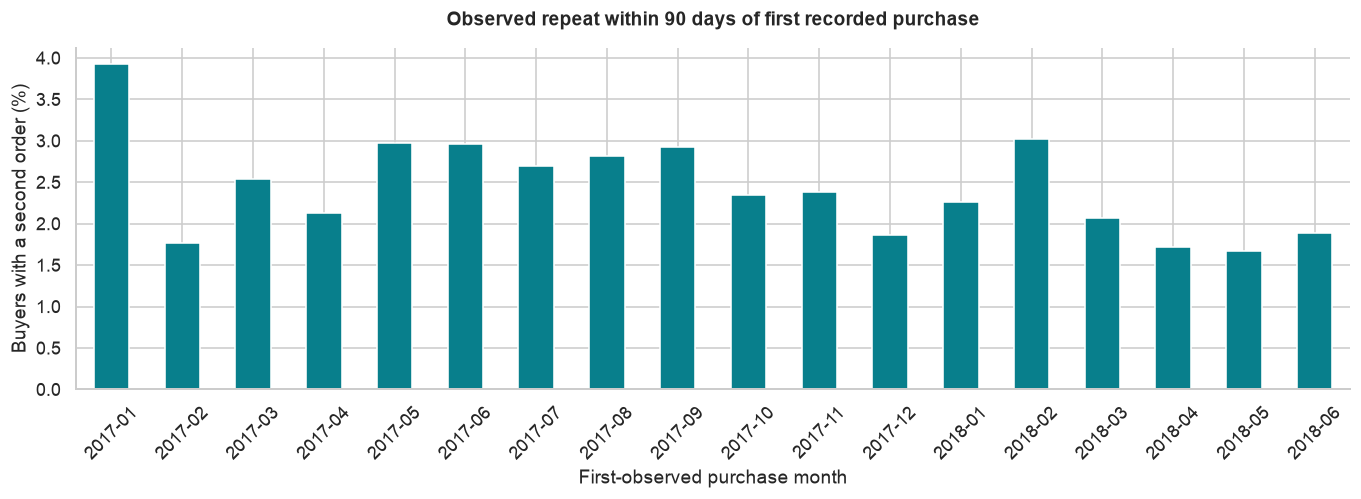

cohort,buyers,repeat_buyers,repeat_pct
2017-01,764,30,3.93
2017-02,"1,752",31,1.77
2017-03,"2,636",67,2.54
2017-04,"2,352",50,2.13
2017-05,"3,596",107,2.98
2017-06,"3,139",93,2.96
2017-07,"3,894",105,2.70
2017-08,"4,184",118,2.82
2017-09,"4,130",121,2.93
2017-10,"4,470",105,2.35


**Fixed-window support:** 77,799 buyers have a 90-day window before the chosen comparison end. Later first purchases are excluded only from this chart. First seen is not necessarily acquisition, and complete source capture cannot be verified. The last eligible month can contain only part of its acquisition dates; counts are shown.

In [26]:
# A fixed 90-day revisit window makes buyer cohorts more comparable.
# Ending at August 31 avoids using the sparse Sep/Oct tail as normal follow-up.
comparison_end=pd.Timestamp('2018-09-01')
first_purchase=buyer_summary['first_purchase']
eligible_buyer=first_purchase.ge('2017-01-01') & (first_purchase+pd.Timedelta(days=90)).lt(comparison_end)
with_first=order_view[['customer_unique_id','order_purchase_timestamp']].merge(first_purchase.rename('first_seen'),on='customer_unique_id',validate='many_to_one')
with_first['within_90']=(with_first['order_purchase_timestamp']>=with_first['first_seen']) & (with_first['order_purchase_timestamp']<=with_first['first_seen']+pd.Timedelta(days=90))
count_90=with_first.loc[with_first['within_90']].groupby('customer_unique_id').size()
cohort_buyers=buyer_summary.loc[eligible_buyer].copy()
cohort_buyers['cohort']=cohort_buyers['first_purchase'].dt.to_period('M').astype(str)
cohort_buyers['repeat_within_90']=count_90.reindex(cohort_buyers.index).gt(1)
cohort_repeat=cohort_buyers.groupby('cohort').agg(buyers=('orders','size'),repeat_buyers=('repeat_within_90','sum'))
cohort_repeat['repeat_pct']=100*cohort_repeat['repeat_buyers']/cohort_repeat['buyers']
fig,ax=plt.subplots(figsize=(12,4.5))
cohort_repeat['repeat_pct'].plot.bar(ax=ax,color=COLORS['teal'],rot=45)
ax.set(title='Observed repeat within 90 days of first recorded purchase',xlabel='First-observed purchase month',ylabel='Buyers with a second order (%)')
plt.tight_layout();plt.show();table(cohort_repeat.reset_index())
note(f"**Fixed-window support:** {len(cohort_buyers):,} buyers have a 90-day window before the chosen comparison end. Later first purchases are excluded only from this chart. First seen is not necessarily acquisition, and complete source capture cannot be verified. The last eligible month can contain only part of its acquisition dates; counts are shown.")


## 13. Geography

**Questions:** Where are customer orders and seller activity concentrated? How does observed delivery vary across states? Is the ZIP-coordinate file trustworthy enough for a descriptive plot?

State is the primary geography. Customer state describes the destination; seller state is a different measure. The ZIP plot uses plot-only aggregation of unique coordinate pairs inside a broad Brazil bounding box. This is not a national-boundary test, a precise address or a cleaned master location table. All original observations remain in memory and on disk.


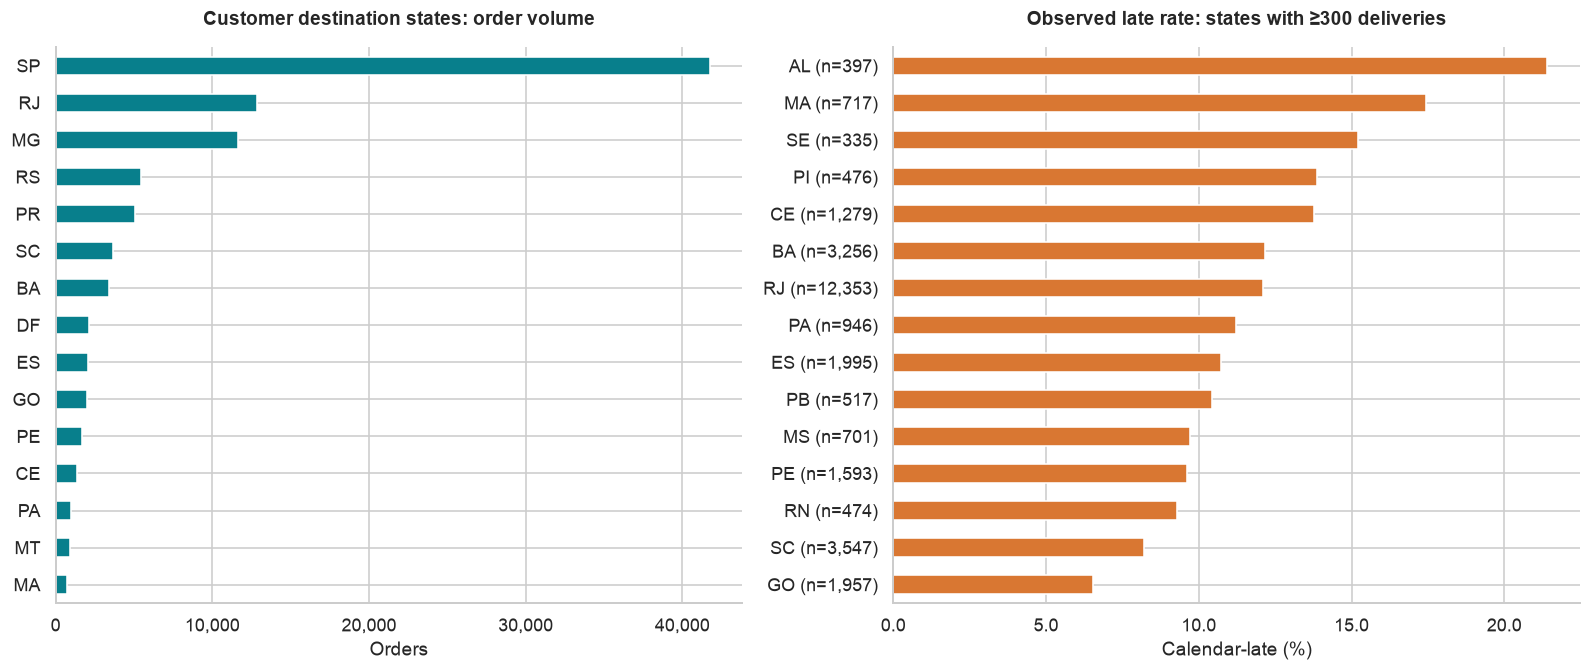

customer_state,orders,item_value,eligible_deliveries,late,median_delivery_days,late_pct
AC,81,"15,982.95",80,3,18.36,3.75
AL,413,"80,314.81",397,85,22.33,21.41
AM,148,"22,356.84",145,4,25.88,2.76
AP,68,"13,474.30",67,2,24.35,2.99
BA,"3,380","511,349.99","3,256",396,16.91,12.16
CE,"1,336","227,254.71","1,279",176,18.21,13.76
DF,"2,140","302,603.94","2,080",118,11.36,5.67
ES,"2,033","275,037.31","1,995",214,13.64,10.73
GO,"2,020","294,591.95","1,957",128,13.95,6.54
MA,747,"119,648.22",717,125,19.19,17.43


Late rates are conditional on observed deliveries and unadjusted for category, seller, date or distance. The 300-delivery display floor reduces tiny-group rankings but does not establish statistical significance. Every state remains in the table.

In [27]:
state_summary=order_view.groupby('customer_state').agg(orders=('order_id','size'),item_value=('item_value',lambda s:s.sum(min_count=1)))
state_delivery=deliveries.groupby('customer_state').agg(eligible_deliveries=('order_id','size'),late=('late_calendar','sum'),median_delivery_days=('delivery_days','median'))
state_summary=state_summary.join(state_delivery)
state_summary['late_pct']=100*state_summary['late']/state_summary['eligible_deliveries']
fig,axes=plt.subplots(1,2,figsize=(14,6))
horizontal_bars(state_summary.nlargest(15,'orders')['orders'],'Customer destination states: order volume','Orders',ax=axes[0])
# Support floor is a descriptive display rule, not a significance guarantee.
supported=state_summary.loc[state_summary['eligible_deliveries'].ge(300)].sort_values('late_pct',ascending=False).head(15)
supported['label']=[f'{idx} (n={int(n):,})' for idx,n in zip(supported.index,supported['eligible_deliveries'])]
horizontal_bars(supported.set_index('label')['late_pct'],'Observed late rate: states with ≥300 deliveries','Calendar-late (%)',color=COLORS['orange'],ax=axes[1])
axes[1].xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.1f}'))
plt.tight_layout();plt.show();table(state_summary.reset_index())
note('Late rates are conditional on observed deliveries and unadjusted for category, seller, date or distance. The 300-delivery display floor reduces tiny-group rankings but does not establish statistical significance. Every state remains in the table.')


Diagnostic,Count
Location rows,"1,000,163"
Exact duplicate rows,"261,831"
Distinct ZIP prefixes,"19,015"
ZIPs with multiple states,8
ZIPs with multiple city spellings,"8,556"
Rows outside broad Brazil box,31


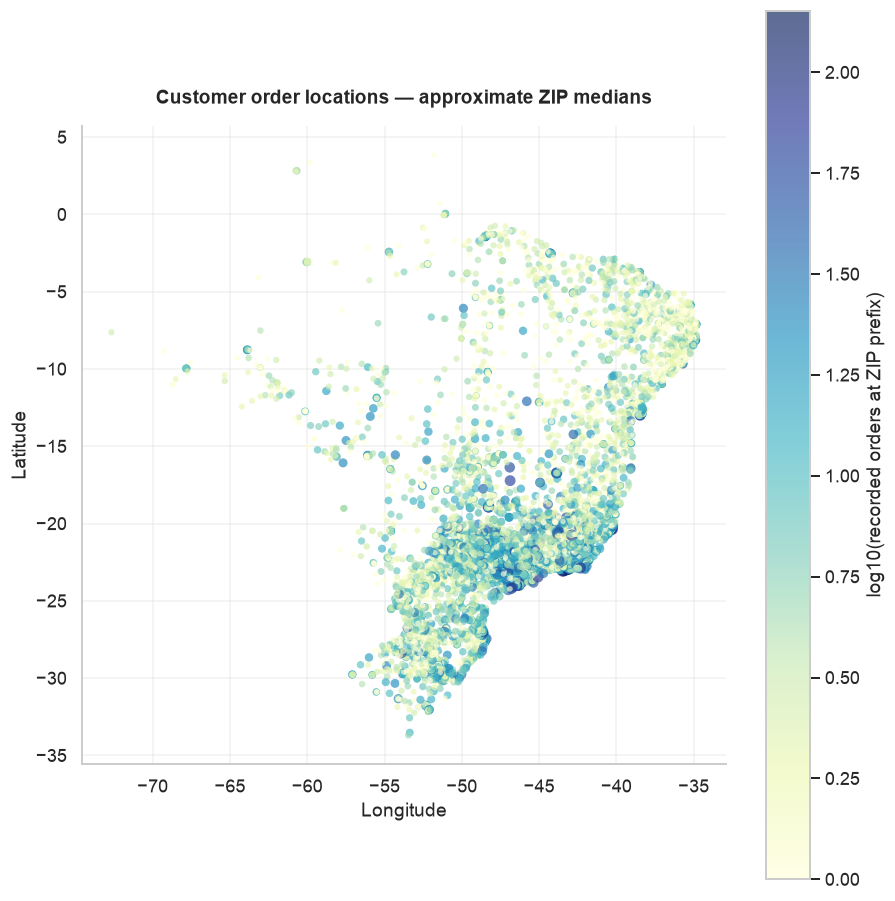

**Coordinate coverage:** 99,162/99,441 orders map to a plot-eligible ZIP median; 279 do not. This coordinate scatter has no external basemap. Median ZIP positions are approximate, potentially ambiguous, and not household locations. Out-of-box observations are excluded only from this plot.

In [28]:
geo_diagnostics=pd.DataFrame({
    'Diagnostic':['Location rows','Exact duplicate rows','Distinct ZIP prefixes','ZIPs with multiple states','ZIPs with multiple city spellings','Rows outside broad Brazil box'],
    'Count':[len(geo),int(geo.duplicated().sum()),geo['geolocation_zip_code_prefix'].nunique(),
             int(geo.groupby('geolocation_zip_code_prefix')['geolocation_state'].nunique().gt(1).sum()),
             int(geo.groupby('geolocation_zip_code_prefix')['geolocation_city'].nunique().gt(1).sum()),
             int((~geo['geolocation_lat'].between(-34,6)|~geo['geolocation_lng'].between(-74,-28)).sum())]})
table(geo_diagnostics)
in_box=geo['geolocation_lat'].between(-34,6)&geo['geolocation_lng'].between(-74,-28)
# Plot-only locations: one median coordinate pair per ZIP after reducing repeated pairs.
geo_plot_source=geo.loc[in_box,['geolocation_zip_code_prefix','geolocation_lat','geolocation_lng']].drop_duplicates()
zip_plot=geo_plot_source.groupby('geolocation_zip_code_prefix').agg(latitude=('geolocation_lat','median'),longitude=('geolocation_lng','median'))
zip_order_counts=order_view.groupby('customer_zip_code_prefix').size().rename('orders')
zip_plot=zip_plot.join(zip_order_counts,how='inner')
fig,ax=plt.subplots(figsize=(8,8))
points=ax.scatter(zip_plot['longitude'],zip_plot['latitude'],c=np.log10(zip_plot['orders']),s=7+5*np.sqrt(zip_plot['orders']),cmap='YlGnBu',alpha=.65,edgecolors='none')
fig.colorbar(points,ax=ax,label='log10(recorded orders at ZIP prefix)')
ax.set(title='Customer order locations — approximate ZIP medians',xlabel='Longitude',ylabel='Latitude')
ax.set_aspect('equal',adjustable='box');ax.grid(alpha=.25)
plt.tight_layout();plt.show()
plotted=int(zip_plot['orders'].sum())
note(f"**Coordinate coverage:** {plotted:,}/{len(order_view):,} orders map to a plot-eligible ZIP median; {len(order_view)-plotted:,} do not. This coordinate scatter has no external basemap. Median ZIP positions are approximate, potentially ambiguous, and not household locations. Out-of-box observations are excluded only from this plot.")


## 14. Exploratory associations

**Question:** Which recorded numeric measurements vary together?

This is descriptive association, not feature selection or model preparation. Spearman correlations summarize monotonic relationships among observed measurements. The matrix uses a declared complete-case cohort so every pair shares the same denominator. That restriction affects only this plot. Delay and delivery duration are mechanically related; both are outcomes, not legitimate checkout-time predictors.


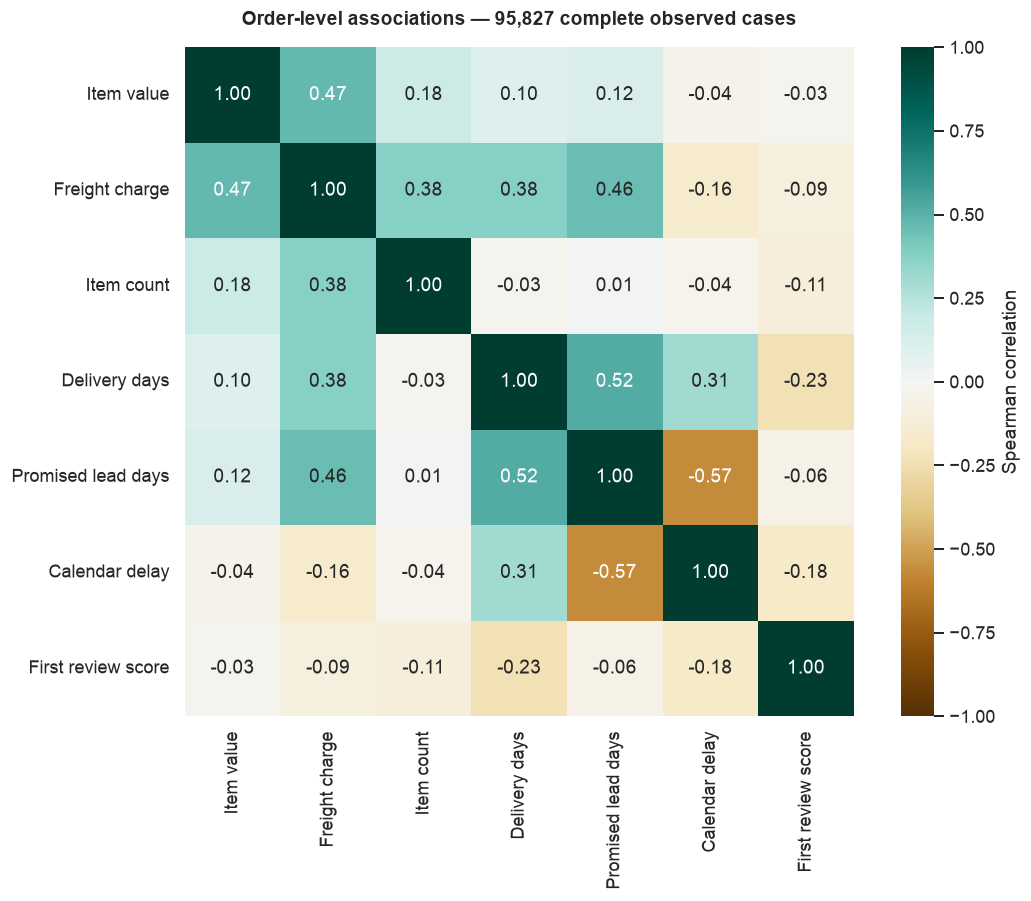

**Eligibility:** 95,827/99,441 orders have all plotted measurements and valid delivery; 3,614 are outside this plot. Complete cases may be selected toward delivered/responding orders. These correlations neither establish causation nor justify future prediction availability.

In [29]:
association_columns={'item_value':'Item value','freight_value':'Freight charge','item_count':'Item count',
                     'delivery_days':'Delivery days','promise_days':'Promised lead days',
                     'delay_calendar_days':'Calendar delay','review_score':'First review score'}
association=order_view.loc[valid_delivery,list(association_columns)].dropna().rename(columns=association_columns)
fig,ax=plt.subplots(figsize=(10,8))
sns.heatmap(association.corr(method='spearman'),annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='BrBG',square=True,ax=ax,cbar_kws={'label':'Spearman correlation'})
ax.set_title(f'Order-level associations — {len(association):,} complete observed cases')
plt.tight_layout();plt.show()
note(f"**Eligibility:** {len(association):,}/{len(order_view):,} orders have all plotted measurements and valid delivery; {len(order_view)-len(association):,} are outside this plot. Complete cases may be selected toward delivered/responding orders. These correlations neither establish causation nor justify future prediction availability.")


## 15. Findings, limitations and source integrity

The summary below is generated from the computations above. It deliberately separates observed evidence from explanations that the dataset cannot establish.


In [30]:
summary=pd.DataFrame([
    ('Source coverage',f'{len(raw)} files; {len(orders):,} orders','Static historical snapshot, not a live data stream'),
    ('Delivery reliability',f'{100*calendar_late.mean():.2f}% calendar-late among {len(deliveries):,} observed deliveries','Unknown delivery is excluded, not treated as on-time'),
    ('Delivery duration',f'Median {deliveries["delivery_days"].median():.1f} days; p90 {deliveries["delivery_days"].quantile(.9):.1f} days','Observed deliveries only'),
    ('Review coverage',f'{len(first_review):,} orders have a valid first answer','Nonrespondents have no inferred score'),
    ('Repeat purchases',f'{100*repeat/len(buyer_summary):.2f}% of observed buyers have multiple orders','Not lifetime retention or loyalty'),
    ('Financial reconciliation',f'{len(different):,} matched orders differ by more than one cent','Amounts are not forced to match'),
    ('Category concentration',f'Top 10 categories: {100*category_summary.head(10)["item_value"].sum()/category_summary["item_value"].sum():.1f}% of item value','Category order counts overlap'),
    ('Geography',f'{plotted:,} orders have a plot-eligible ZIP median','Coordinates approximate; state summaries remain primary'),
],columns=['Topic','Observed evidence','Interpretation limit'])
table(summary)
note('''
### What can be concluded
- Correct table grain matters: multiple items, payments and reviews can otherwise inflate totals.
- Delivery, review and payment timing require explicit definitions and eligibility counts.
- Long-tailed value distributions, uneven category/seller activity and sparse repeat purchasing are descriptive patterns worth discussing.
- Early/late sparse periods and unequal follow-up limit time comparisons.

### What cannot be concluded
- Profit, inventory levels, returns, settlement cash flow, true demand, causal effects or customer lifetime value are not established by these nine files.
- Missing outcomes do not imply success or failure, and final statuses do not reconstruct all historical transitions.
- No model readiness, predictive performance or business intervention effectiveness has been tested.

### Work intentionally not performed
No global cleaning, numeric imputation, outlier deletion, encoding, scaling, training features, train/test split, modeling or deployment. Temporary analysis views and plot-specific masks are not exported as a cleaned dataset.
''')


Topic,Observed evidence,Interpretation limit
Source coverage,"9 files; 99,441 orders","Static historical snapshot, not a live data stream"
Delivery reliability,"6.77% calendar-late among 96,476 observed deliveries","Unknown delivery is excluded, not treated as on-time"
Delivery duration,Median 10.2 days; p90 23.1 days,Observed deliveries only
Review coverage,"98,613 orders have a valid first answer",Nonrespondents have no inferred score
Repeat purchases,3.12% of observed buyers have multiple orders,Not lifetime retention or loyalty
Financial reconciliation,303 matched orders differ by more than one cent,Amounts are not forced to match
Category concentration,Top 10 categories: 62.4% of item value,Category order counts overlap
Geography,"99,162 orders have a plot-eligible ZIP median",Coordinates approximate; state summaries remain primary



### What can be concluded
- Correct table grain matters: multiple items, payments and reviews can otherwise inflate totals.
- Delivery, review and payment timing require explicit definitions and eligibility counts.
- Long-tailed value distributions, uneven category/seller activity and sparse repeat purchasing are descriptive patterns worth discussing.
- Early/late sparse periods and unequal follow-up limit time comparisons.

### What cannot be concluded
- Profit, inventory levels, returns, settlement cash flow, true demand, causal effects or customer lifetime value are not established by these nine files.
- Missing outcomes do not imply success or failure, and final statuses do not reconstruct all historical transitions.
- No model readiness, predictive performance or business intervention effectiveness has been tested.

### Work intentionally not performed
No global cleaning, numeric imputation, outlier deletion, encoding, scaling, training features, train/test split, modeling or deployment. Temporary analysis views and plot-specific masks are not exported as a cleaned dataset.


In [31]:
final_hashes={filename:hashlib.sha256((DATA_DIR/filename).read_bytes()).hexdigest() for filename in FILES.values()}
assert initial_hashes==final_hashes, 'Source files changed during the analysis.'
assert len(order_view)==len(orders) and order_view['order_id'].is_unique
assert np.isclose(items['price'].sum(),category_summary['item_value'].sum())
for name in raw:
    # Working transformations must not change the raw frame schema or row counts.
    assert len(raw[name])==int(manifest.loc[manifest['Table'].eq(name),'Rows'].iloc[0])
table(pd.DataFrame({'Check':['All nine source file hashes unchanged','Order view preserves one row per order','Category item-value totals reconcile','No derived CSV or cleaned dataset export'],
                    'Result':['PASS','PASS','PASS','No export operations in this notebook']}))
note('**EDA complete.** The notebook contains executed descriptive analysis and visualizations only. All source CSVs remain unchanged.')
# Source fingerprints are useful when reproducing this exact analysis.
table(manifest[['File','SHA256']])


Check,Result
All nine source file hashes unchanged,PASS
Order view preserves one row per order,PASS
Category item-value totals reconcile,PASS
No derived CSV or cleaned dataset export,No export operations in this notebook


**EDA complete.** The notebook contains executed descriptive analysis and visualizations only. All source CSVs remain unchanged.

File,SHA256
olist_orders_dataset.csv,8df58ef3d2d7e9944010f7beecd9b75367f5588ec6e3c91cec19ae3345ef9ecf
olist_order_items_dataset.csv,0bc4d068c4fe38cbb01bd90e8746e3c613fe7b4baef75fab7b0e329701c3e279
olist_order_payments_dataset.csv,4f713964f2815dbbaa40b9488268c55aac3627bfce5aa96cf58d1f3616de3cc0
olist_order_reviews_dataset.csv,012b61c7593e34f51fa614efdf802b9c7056ce6aae5307ddb93236e7cfc797d7
olist_customers_dataset.csv,983a422239e1712ded753b3bf9ecf47dc73f144d306029dcfa99e70a226883d2
olist_products_dataset.csv,3e6569628a17fbc75fd206ee357b59e20364b9afa90f5b6cd5b4d624c58aa9cc
olist_sellers_dataset.csv,1f643d2b950373b85735e7794b20986f528d7a000432e7c6f9bcbb44d0846a0e
olist_geolocation_dataset.csv,b514f6fc991b9566aeba02aa5d67e2c3630f034b60a0e05aa0d082a3b66d88d6
product_category_name_translation.csv,a81f0d1f27b27e7293f761bc79e3ce8f348ee39c4b3ed3e49bde38f478586278
